<img src=Images/Banner3.png width=500 >

# **Table of contents**<a id='toc0_'></a>    
- [Human Activity Recognition - UCI HAR](#toc1_)    
  - [Data Preprocessing](#toc1_1_)    
  - [MLP Architecture Design](#toc1_2_)    
  - [CNN Architecture Design](#toc1_3_)
  - [Model Evaluation and Comparison](#toc1_4_)    
   
- [NEU Surface Defects](#toc2_)    
  - [Data Preprocessing](#toc2_1_)    
  - [MLP Architecture Design](#toc2_2_) 
  - [CNN Architecture Design](#toc2_3_) 
  - [Fine-Tuned CNN Architecture Design](#toc2_4_) 
  - [ResNet-50 Model Design](#toc2_5_) 
  - [Comparison](#toc2_6_) 

---


## <a id='toc1_'></a>[Human Activity Recognition - UCI HAR](#toc0_)  

### <a id='toc1_1_'></a>[Data Preprocessing](#toc0_)  

> The first task is to load and preprocess data so that its shape and format is appropriate for MLP. These are the steps that need to be taken:
1. Load the data: Load the numerical text data from `train` and `test` files. Also `activity_labels.txt` is used to mapp each label to corresponding activity.
2. Split the data: After having train and test data, we will further split the train data into train and validation. Train data and validation will be used for the training process and the test data will perform as the last evaluation.
3. Scale the data: We will use `Min-Max` scaling to map features to a fixed range, between 0 and 1.

**Note** : After attemps to fit the model, we figured out that We also need to adjust the values of y since later tensorflow will ask for 0-indexed labels and our indexes are 1-indexed.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
## Load the data - Define function to handle reading txt data

DATASET_PATH = 'UCI HAR Dataset/' 

def load_har_data(dataset_path):

    with open(os.path.join(dataset_path, 'features.txt'), 'r') as f:
        features = [line.strip().split() for line in f]
    feature_names = [feature[1] for feature in features]

    with open(os.path.join(dataset_path, 'activity_labels.txt'), 'r') as f:
        activities = [line.strip().split() for line in f]
    activity_labels = {int(a[0]): a[1] for a in activities}

    X_train_path = os.path.join(dataset_path, 'train', 'X_train.txt')
    y_train_path = os.path.join(dataset_path, 'train', 'y_train.txt')
    subject_train_path = os.path.join(dataset_path, 'train', 'subject_train.txt')

    X_train = np.loadtxt(X_train_path)
    y_train = np.loadtxt(y_train_path, dtype=int)
    subject_train = np.loadtxt(subject_train_path, dtype=int)

    X_test_path = os.path.join(dataset_path, 'test', 'X_test.txt')
    y_test_path = os.path.join(dataset_path, 'test', 'y_test.txt')
    subject_test_path = os.path.join(dataset_path, 'test', 'subject_test.txt')

    X_test = np.loadtxt(X_test_path)
    y_test = np.loadtxt(y_test_path, dtype=int)
    subject_test = np.loadtxt(subject_test_path, dtype=int)

    return X_train, y_train, subject_train, X_test, y_test, subject_test, feature_names, activity_labels

In [3]:
## Read the data using function and split the data into train, validation and test

from sklearn.model_selection import train_test_split

X, y, subject_train, X_test, y_test, subject_test, feature_names, activity_labels = load_har_data(DATASET_PATH)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify= y )




print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")

print(f"X_train shape: {X_val.shape}")
print(f"y_train shape: {y_val.shape}")

print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

print(f"Number of features: {len(feature_names)}")
print(f"Activities: {activity_labels}")

X_train shape: (6249, 561)
y_train shape: (6249,)
X_train shape: (1103, 561)
y_train shape: (1103,)
X_test shape: (2947, 561)
y_test shape: (2947,)
Number of features: 561
Activities: {1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS', 4: 'SITTING', 5: 'STANDING', 6: 'LAYING'}


In [4]:
# --- Correct Labeling (NEW) ---

# Subtract 1 from all activity labels to make them 0-indexed
y_train_adjusted = y_train - 1
y_val_adjusted = y_val - 1
y_test_adjusted = y_test - 1 


print("\nActivity labels adjusted to be 0-indexed:")
print(f"Original y_train min/max: {y_train.min()}/{y_train.max()}")
print(f"Adjusted y_train min/max: {y_train_adjusted.min()}/{y_train_adjusted.max()}")


Activity labels adjusted to be 0-indexed:
Original y_train min/max: 1/6
Adjusted y_train min/max: 0/5


In [4]:
## Min-Max Scaling

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


### <a id='toc1_2_'></a>[MLP Architecture Design](#toc0_)  

> In this part we will explore elements of our MLP network and why we chose each element:
- Overall Architecture: 1.1 Input layer where the size is the dimension of our features which is 561. After that 2 hidden layers with 256 and 128 neurons with dropout to avoid overfitting. The final layer is the output layer which has 6 neurons (same as number of classes).
- Activation Functions: Relu for hidden layers since it is most commonly used activation function for hidden layers in deep neural networks. It introduces non-linearity, allowing the network to learn complex patterns that linear models cannot.Since this is a multi-class classification problem (identifying one of 6 activities), softmax is the ideal choice for the output layer. It converts the raw outputs (logits) of the neural network into a probability distribution over the classes. Each output value will be between 0 and 1, and the sum of all output values will be 1.
- Loss Function: sparse_categorical_crossentropy is used because our y_train and y_val labels are integer-encoded (1, 2, 3, 4, 5, 6).

In [5]:
import tensorflow as tf
from tensorflow.keras import models
from tensorflow.keras import layers

## Define model Hyperparameters

input_shape = X_train_scaled.shape[1] 

num_classes = len(activity_labels)

dropout_rate = 0.3 

# Build the Sequential Model
mlp_model = models.Sequential([

    # First Hidden Layer, (The input layer is the shape of features itself)
    layers.Dense(units=256, activation='relu', input_shape=(input_shape,), name='hidden_layer_1'),
    layers.Dropout(dropout_rate, name='dropout_1'), 

    # Second Hidden Layer
    layers.Dense(units=128, activation='relu', name='hidden_layer_2'),
    layers.Dropout(dropout_rate, name='dropout_2'), 

    # Output Layer
    layers.Dense(units=num_classes, activation='softmax', name='output_layer')
])

# Compile the model
mlp_model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

mlp_model.summary()

2025-05-26 17:55:36.958990: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 hidden_layer_1 (Dense)      (None, 256)               143872    
                                                                 
 dropout_1 (Dropout)         (None, 256)               0         
                                                                 
 hidden_layer_2 (Dense)      (None, 128)               32896     
                                                                 
 dropout_2 (Dropout)         (None, 128)               0         
                                                                 
 output_layer (Dense)        (None, 6)                 774       
                                                                 
Total params: 177,542
Trainable params: 177,542
Non-trainable params: 0
_________________________________________________________________


2025-05-26 17:55:38.132830: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [7]:
## Fit the model


from tensorflow.keras import optimizers 

## Training Hyperparameters

learning_rate = 0.001
adam_optimizer = optimizers.Adam(learning_rate=learning_rate)

mlp_model.compile(optimizer=adam_optimizer, 
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])



epochs = 20
batch_size = 32 

history_mlp = mlp_model.fit(
    X_train_scaled, y_train_adjusted, 
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val_scaled, y_val_adjusted), 
    verbose=1
)


Epoch 1/20
196/196 [==============================] - 1s 3ms/step - loss: 0.6505 - accuracy: 0.7188 - val_loss: 0.2404 - val_accuracy: 0.9075
Epoch 2/20
196/196 [==============================] - 1s 3ms/step - loss: 0.2875 - accuracy: 0.8825 - val_loss: 0.1926 - val_accuracy: 0.9257
Epoch 3/20
196/196 [==============================] - 1s 3ms/step - loss: 0.2099 - accuracy: 0.9189 - val_loss: 0.1357 - val_accuracy: 0.9510
Epoch 4/20
196/196 [==============================] - 1s 3ms/step - loss: 0.1671 - accuracy: 0.9352 - val_loss: 0.1427 - val_accuracy: 0.9447
Epoch 5/20
196/196 [==============================] - 0s 2ms/step - loss: 0.1449 - accuracy: 0.9422 - val_loss: 0.1045 - val_accuracy: 0.9565
Epoch 6/20
196/196 [==============================] - 0s 2ms/step - loss: 0.1497 - accuracy: 0.9421 - val_loss: 0.1083 - val_accuracy: 0.9565
Epoch 7/20
196/196 [==============================] - 0s 2ms/step - loss: 0.1220 - accuracy: 0.9539 - val_loss: 0.1028 - val_accuracy: 0.9610
Epoch 

In [8]:
sns.set_theme(style="darkgrid")


/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be rem

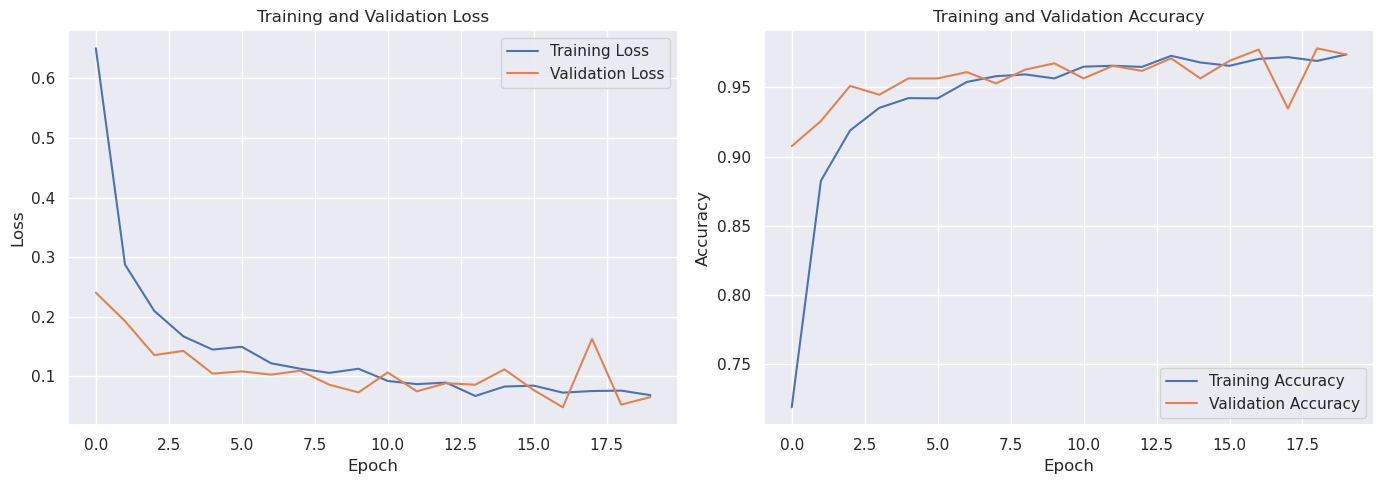

In [9]:
### Plot acc and loss


epochs_range = range(epochs) 
train_loss = history_mlp.history['loss']
val_loss = history_mlp.history['val_loss']
train_accuracy = history_mlp.history['accuracy']
val_accuracy = history_mlp.history['val_accuracy']

plt.figure(figsize=(14, 5))

# Plot Training and Validation Loss
plt.subplot(1, 2, 1) 
sns.lineplot(x=epochs_range, y=train_loss, label='Training Loss')
sns.lineplot(x=epochs_range, y=val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Plot Training and Validation Accuracy
plt.subplot(1, 2, 2) 
sns.lineplot(x=epochs_range, y=train_accuracy, label='Training Accuracy')
sns.lineplot(x=epochs_range, y=val_accuracy, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout() # Adjusts plot parameters for a tight layout
plt.show()



In [10]:
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score

test_loss, test_accuracy = mlp_model.evaluate(X_test_scaled, y_test_adjusted, verbose=0)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


y_pred_probs = mlp_model.predict(X_test_scaled, verbose=0)

y_pred = np.argmax(y_pred_probs, axis=1)

sorted_activity_names = [activity_labels[i+1] for i in range(len(activity_labels))]

print(classification_report(y_test_adjusted, y_pred, target_names=sorted_activity_names))


print(f"\nOverall Test Accuracy (from sklearn): {accuracy_score(y_test_adjusted, y_pred):.4f}")
print(f"Weighted Precision: {precision_score(y_test_adjusted, y_pred, average='weighted'):.4f}")
print(f"Weighted Recall: {recall_score(y_test_adjusted, y_pred, average='weighted'):.4f}")
print(f"Weighted F1-Score: {f1_score(y_test_adjusted, y_pred, average='weighted'):.4f}")


Test Loss: 0.1184
Test Accuracy: 0.9610
                    precision    recall  f1-score   support

           WALKING       0.96      0.99      0.97       496
  WALKING_UPSTAIRS       0.95      0.96      0.95       471
WALKING_DOWNSTAIRS       0.98      0.95      0.96       420
           SITTING       0.93      0.93      0.93       491
          STANDING       0.94      0.94      0.94       532
            LAYING       1.00      1.00      1.00       537

          accuracy                           0.96      2947
         macro avg       0.96      0.96      0.96      2947
      weighted avg       0.96      0.96      0.96      2947


Overall Test Accuracy (from sklearn): 0.9610
Weighted Precision: 0.9611
Weighted Recall: 0.9610
Weighted F1-Score: 0.9610


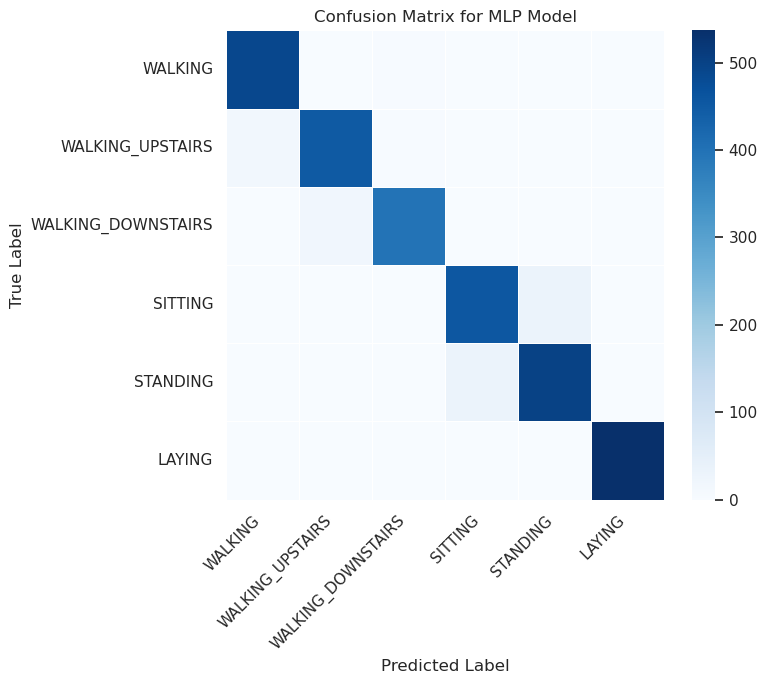

In [11]:
## Confusion Matrix


from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_adjusted, y_pred)

plt.figure(figsize=(8, 7))
sns.heatmap(cm,
                   
            fmt='d',           
            cmap='Blues',      
            xticklabels=sorted_activity_names, 
            yticklabels=sorted_activity_names,
            linewidths=.5,     
            cbar=True,
            annot_kws={"size": 10})        

plt.title('Confusion Matrix for MLP Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right') 
plt.yticks(rotation=0)             
plt.tight_layout()
plt.show()

**Since i was unable to print annotations on the confusion matrix, i will do them manually**

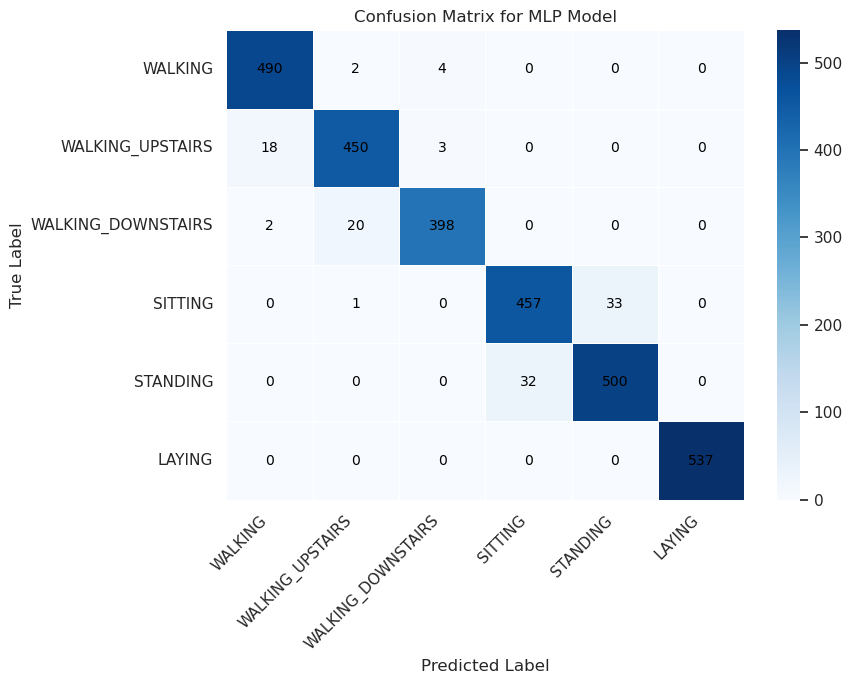

In [12]:
plt.figure(figsize=(9, 7))
ax = sns.heatmap(cm,
                 annot=False,
                 cmap='Blues',
                 xticklabels=sorted_activity_names,
                 yticklabels=sorted_activity_names,
                 linewidths=.5,
                 cbar=True)

# Manually annotate each cell
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        text = ax.text(j + 0.5, i + 0.5, str(cm[i, j]),
                       ha='center', va='center',
                       color='black', fontsize=10)

plt.title('Confusion Matrix for MLP Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### <a id='toc1_3_'></a>[CNN Architecture Design](#toc0_)  

> Just like a 2D CNN learns edges and textures in images, a 1D CNN learns temporal patterns or sequential correlations in time-series data. It can detect specific movements, repetitions, or characteristic signal shapes within the feature vector. So CNN can be used to classify the human activity.
- Timestamp; 561 features as "timesteps" and 1 feature per timestep.
- Input layer shape: This is crucial. Conv1D layers expect a 3D input tensor (batch_size, timesteps, channels/features). Your X_train_scaled is (samples, 561). We reshape (samples, 561) to (samples, 561, 1) to explicitly tell the Conv1D layer that it should treat the 561 features as a sequence of 561 "timesteps", each with 1 feature channel.
- Hidden layers: 2 Convolutional Blocks with 64 and then 128 filters with kernel size = 3, Batch normalization and Maxpooling 1D.
- Flatten layer: Flatten the output of convolutional layers before feeding to Dense layers.
- FC: Standard fully connected layers that operate on the flattened features. They learn higher-level combinations of the features extracted by the convolutional layers.


In [13]:
## Hyperparameters of the network

input_timesteps = X_train_scaled.shape[1] 
input_features = 1 

num_classes = len(activity_labels) 

# Build the Sequential Model
cnn_model_1 = models.Sequential([
    # Reshape layer
    layers.Reshape((input_timesteps, input_features), input_shape=(input_timesteps,), name='reshape_input'),

    # First Convolutional Block
    layers.Conv1D(filters=64, kernel_size=3, activation='linear', padding='same', name='conv1d_1'),
    layers.BatchNormalization(name='batch_norm_1'), 
    layers.Activation('relu', name='relu_1'),      
    layers.MaxPooling1D(pool_size=2, name='max_pool_1'),
    layers.Dropout(0.25, name='dropout_1'),         

    # Second Convolutional Block
    layers.Conv1D(filters=128, kernel_size=3, activation='linear', padding='same', name='conv1d_2'),
    layers.BatchNormalization(name='batch_norm_2'), 
    layers.Activation('relu', name='relu_2'),      
    layers.MaxPooling1D(pool_size=2, name='max_pool_2'), 
    layers.Dropout(0.25, name='dropout_2'),          

    # Flatten the output of convolutional layers before feeding to Dense layers
    layers.Flatten(name='flatten'),

    # Fully Connected (Dense) Layers for Classification
    layers.Dense(units=64, activation='linear', name='dense_1'),
    layers.BatchNormalization(name='batch_norm_3'),
    layers.Activation('relu', name='relu_3'),
    layers.Dropout(0.5, name='dropout_3'),

    # Output Layer
    layers.Dense(units=num_classes, activation='softmax', name='output_layer')
])

# Compile the model
learning_rate_cnn = 0.001
adam_optimizer_cnn = optimizers.Adam(learning_rate=learning_rate_cnn)

cnn_model_1.compile(optimizer=adam_optimizer_cnn,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

print("CNN Model Architecture Designed and Compiled!")
cnn_model_1.summary()

CNN Model Architecture Designed and Compiled!
Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 reshape_input (Reshape)     (None, 561, 1)            0         
                                                                 
 conv1d_1 (Conv1D)           (None, 561, 64)           256       
                                                                 
 batch_norm_1 (BatchNormaliz  (None, 561, 64)          256       
 ation)                                                          
                                                                 
 relu_1 (Activation)         (None, 561, 64)           0         
                                                                 
 max_pool_1 (MaxPooling1D)   (None, 280, 64)           0         
                                                                 
 dropout_1 (Dropout)         (None, 280, 64)           0         
        

In [14]:
##Define training parameters

epochs = 20
batch_size = 32 
print("\nStarting CNN Model Training...")
history_cnn = cnn_model_1.fit(
    X_train_scaled, y_train_adjusted,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val_scaled, y_val_adjusted),
    verbose=1 )


Starting CNN Model Training...
Epoch 1/20
196/196 [==============================] - 14s 65ms/step - loss: 0.4760 - accuracy: 0.8371 - val_loss: 2.5062 - val_accuracy: 0.1668
Epoch 2/20
196/196 [==============================] - 13s 69ms/step - loss: 0.2062 - accuracy: 0.9334 - val_loss: 1.6487 - val_accuracy: 0.3581
Epoch 3/20
196/196 [==============================] - 13s 68ms/step - loss: 0.1560 - accuracy: 0.9507 - val_loss: 0.1911 - val_accuracy: 0.9293
Epoch 4/20
196/196 [==============================] - 14s 69ms/step - loss: 0.1288 - accuracy: 0.9562 - val_loss: 0.0607 - val_accuracy: 0.9819
Epoch 5/20
196/196 [==============================] - 14s 70ms/step - loss: 0.1152 - accuracy: 0.9597 - val_loss: 0.0573 - val_accuracy: 0.9791
Epoch 6/20
196/196 [==============================] - 12s 60ms/step - loss: 0.1015 - accuracy: 0.9653 - val_loss: 0.0588 - val_accuracy: 0.9782
Epoch 7/20
196/196 [==============================] - 12s 59ms/step - loss: 0.0920 - accuracy: 0.9677 - 

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be rem

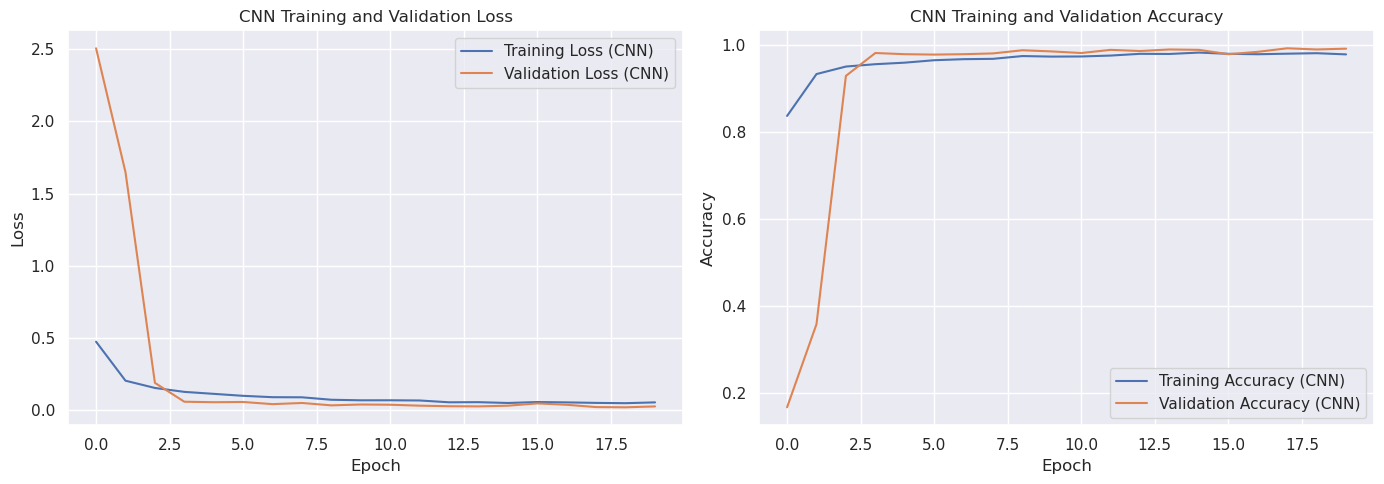

In [15]:
## plot acc and loss vs epoch

epochs_range = range(epochs)

train_loss_cnn = history_cnn.history['loss']
val_loss_cnn = history_cnn.history['val_loss']
train_accuracy_cnn = history_cnn.history['accuracy']
val_accuracy_cnn = history_cnn.history['val_accuracy']

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1) 
sns.lineplot(x=epochs_range, y=train_loss_cnn, label='Training Loss (CNN)')
sns.lineplot(x=epochs_range, y=val_loss_cnn, label='Validation Loss (CNN)')
plt.title('CNN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2) 
sns.lineplot(x=epochs_range, y=train_accuracy_cnn, label='Training Accuracy (CNN)')
sns.lineplot(x=epochs_range, y=val_accuracy_cnn, label='Validation Accuracy (CNN)')
plt.title('CNN Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout() 
plt.show()


In [16]:
## Evaluation on the test data


test_loss_cnn, test_accuracy_cnn = cnn_model_1.evaluate(X_test_scaled, y_test_adjusted, verbose=0)

print(f"\nCNN Test Loss: {test_loss_cnn:.4f}")
print(f"CNN Test Accuracy: {test_accuracy_cnn:.4f}")


y_pred_probs_cnn = cnn_model_1.predict(X_test_scaled, verbose=0)

y_pred_cnn = np.argmax(y_pred_probs_cnn, axis=1)


print("\n--- CNN Detailed Classification Report ---")
print(classification_report(y_test_adjusted, y_pred_cnn, target_names=sorted_activity_names))

print(f"\nCNN Overall Test Accuracy (from sklearn): {accuracy_score(y_test_adjusted, y_pred_cnn):.4f}")
print(f"CNN Weighted Precision: {precision_score(y_test_adjusted, y_pred_cnn, average='weighted'):.4f}")
print(f"CNN Weighted Recall: {recall_score(y_test_adjusted, y_pred_cnn, average='weighted'):.4f}")
print(f"CNN Weighted F1-Score: {f1_score(y_test_adjusted, y_pred_cnn, average='weighted'):.4f}")


CNN Test Loss: 0.1331
CNN Test Accuracy: 0.9562

--- CNN Detailed Classification Report ---
                    precision    recall  f1-score   support

           WALKING       0.91      1.00      0.95       496
  WALKING_UPSTAIRS       0.95      0.94      0.94       471
WALKING_DOWNSTAIRS       1.00      0.90      0.95       420
           SITTING       0.96      0.93      0.94       491
          STANDING       0.94      0.96      0.95       532
            LAYING       1.00      1.00      1.00       537

          accuracy                           0.96      2947
         macro avg       0.96      0.95      0.96      2947
      weighted avg       0.96      0.96      0.96      2947


CNN Overall Test Accuracy (from sklearn): 0.9562
CNN Weighted Precision: 0.9578
CNN Weighted Recall: 0.9562
CNN Weighted F1-Score: 0.9562


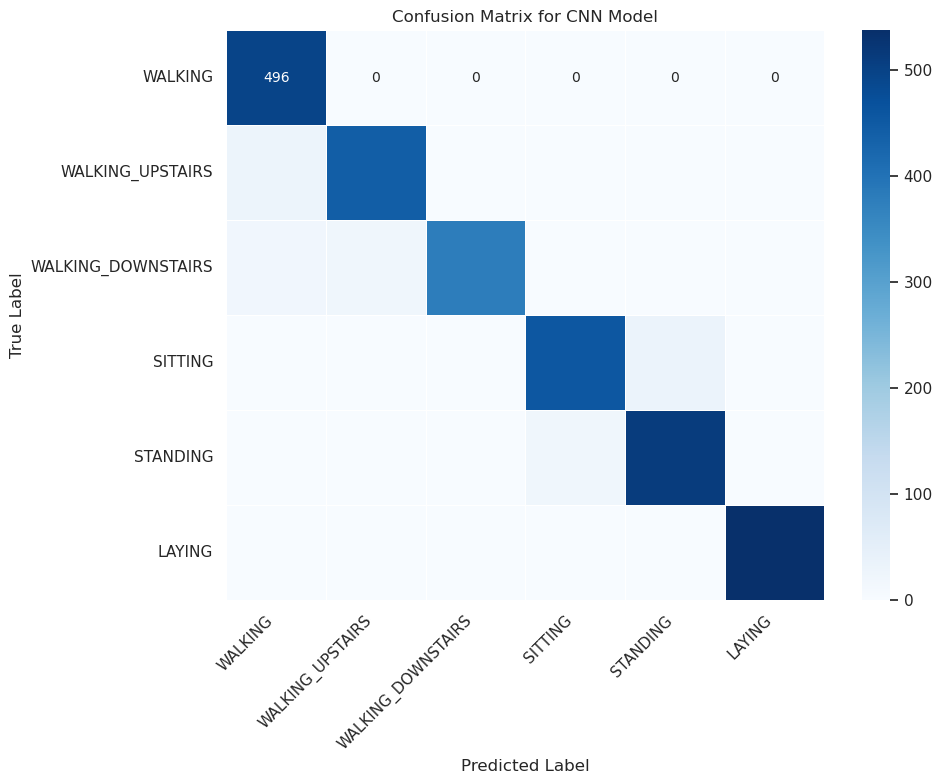

In [17]:

cm_cnn = confusion_matrix(y_test_adjusted, y_pred_cnn)


plt.figure(figsize=(10, 8)) 
sns.heatmap(cm_cnn,
            annot=True,       
            fmt='d',           
            cmap='Blues',      
            xticklabels=sorted_activity_names,
            yticklabels=sorted_activity_names,
            linewidths=.5,     
            cbar=True,     
            annot_kws={"size": 10}) 

plt.title('Confusion Matrix for CNN Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



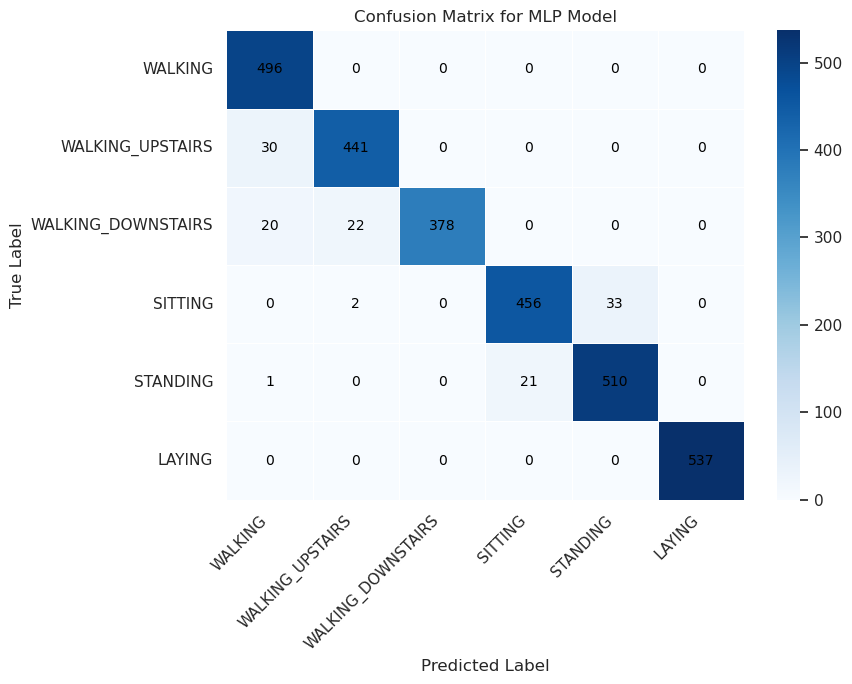

In [18]:
plt.figure(figsize=(9, 7))
ax = sns.heatmap(cm_cnn,
                 annot=False,
                 cmap='Blues',
                 xticklabels=sorted_activity_names,
                 yticklabels=sorted_activity_names,
                 linewidths=.5,
                 cbar=True)

# Manually annotate each cell
for i in range(cm_cnn.shape[0]):
    for j in range(cm_cnn.shape[1]):
        text = ax.text(j + 0.5, i + 0.5, str(cm_cnn[i, j]),
                       ha='center', va='center',
                       color='black', fontsize=10)

plt.title('Confusion Matrix for MLP Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### <a id='toc1_4_'></a>[Model Evaluation and Comparison](#toc0_)  

Both (MLP) and Convolutional Neural Network (CNN) models demonstrate excellent performance on the UCI Human Activity Recognition (HAR) dataset. While both achieve high accuracy, there are notable differences in their architecture, efficiency, and specific strengths.

## 1. Overall Performance (Accuracy & Loss)
MLP:
Test Loss: 0.1184
Test Accuracy: 0.9610
Weighted F1-Score: 0.9610
CNN:
Test Loss: 0.1331
Test Accuracy: 0.9562
Weighted F1-Score: 0.9562
The MLP model marginally outperforms the CNN in terms of overall test accuracy and F1-score, achieving about 0.5% higher accuracy. It also has a slightly lower test loss, indicating a better fit to the underlying data distribution on the test set.

## 2. Model Complexity (Parameters)
MLP:
Total Parameters: 177,542
Trainable Parameters: 177,542
CNN:
Total Parameters: 1,173,318
Trainable Parameters: 1,172,806
The CNN is significantly more complex, with approximately 6.6 times more trainable parameters than the MLP. This larger number of parameters in the CNN is primarily due to the convolutional filters and the subsequent flattening of the feature maps before feeding into the final dense layers. Batch Normalization layers also introduce a small number of non-trainable parameters (mean and variance).

## 3. Strengths in Activity Classification (Precision, Recall, F1-Score per Class)

In general, both models handle the distinct activities like 'LAYING' exceptionally well. The dynamic activities ('WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS') are also well-classified by both.

## 4. Training Speed and Efficiency
While direct training time was not provided, we can infer some aspects:

MLP: With fewer parameters, an MLP typically trains faster per epoch than a CNN. Its simpler architecture involves straightforward matrix multiplications.
CNN: Despite its higher parameter count, CNNs benefit from weight sharing (the same filter applied across different parts of the input), which can make them computationally efficient for learning local patterns. However, the sheer number of operations (convolutions, pooling) can still make each epoch slower than an MLP. Given that the MLP achieved slightly better accuracy with far fewer parameters, it suggests it might be more computationally efficient for this specific dataset and feature set.
## 5. Applicability to Data Type
MLP: MLPs are universal function approximators and can learn complex relationships in any tabular or flattened data. They are well-suited for the 561-feature vector, treating it as a flat input.
CNN: As discussed earlier, CNNs are highly effective for data with spatial or sequential locality, even if not explicitly "images." The 1D convolutions on the 561-feature vector implicitly exploit any local patterns or ordering within the features. While your MLP performed slightly better, the fact that a CNN could achieve comparable results on highly engineered, non-raw sensor features validates its applicability. If you were working directly with the raw time-series accelerometer/gyroscope signals, a CNN would likely show a more significant advantage due to its natural ability to process sequential data directly.
## Conclusion
Both models are highly effective for the UCI HAR dataset. Your MLP model demonstrates a slight edge in overall accuracy and loss with a significantly more compact architecture (fewer parameters). This makes the MLP the more "efficient" choice in this specific comparison, as it achieves slightly better performance with substantially less complexity.

The CNN, while more complex, also performs admirably, validating its use on structured non-image data. Its power often shines when dealing with raw time-series data or when features inherently have strong local spatial/temporal correlations that a CNN can automatically discover through its filters. For this particular pre-processed dataset, the MLP's ability to map the combined features to outputs appears to be marginally more effective.

___

## <a id='toc2_'></a>[NEU Surface Defect](#toc0_)  

### <a id='toc2_1_'></a>[Data Preprocessing](#toc0_)  

> Preprocessing of this data is exactly like the previous part.
- Spliting data: First all images from the two folders are loaded and merged into 1 dataset. After that data is divided into train, validation and test with the ration of 15% for validation and test.
- Scaling: For image data with pixel values typically ranging from 0 to 255, Min-Max scaling is straightforward: you divide all pixel values by the maximum possible value, which is 255. This normalizes the data to the range [0, 1].
It's crucial to convert the data type to float before division to ensure proper floating-point calculations

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
import cv2
from tensorflow.keras import models
from tensorflow.keras import layers
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score
from tensorflow.keras import optimizers 



# Load and Split the dataset


## Defining hyperparametrs such as image size and ...

DATASET_PATH = 'NEU-DET/'

IMG_HEIGHT = 200 
IMG_WIDTH = 200
BATCH_SIZE_LOAD = 32 

### Load all images

train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_PATH, 'train', 'images'),
    labels='inferred',       
    label_mode='int',         
    color_mode='grayscale',   
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    interpolation='nearest', 
    batch_size=BATCH_SIZE_LOAD,
    shuffle=False             
)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_PATH, 'validation', 'images'),
    labels='inferred',
    label_mode='int',
    color_mode='grayscale',
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    interpolation='nearest',
    batch_size=BATCH_SIZE_LOAD,
    shuffle=False
)

class_names = train_ds_raw.class_names
num_classes = len(class_names)
print(f"Detected classes: {class_names}")
print(f"Number of classes: {num_classes}")

## Merge all of images


all_images = []
all_labels = []

for images, labels in train_ds_raw:
    all_images.append(images.numpy())
    all_labels.append(labels.numpy())

for images, labels in val_ds_raw:
    all_images.append(images.numpy())
    all_labels.append(labels.numpy())

# Concatenate all batches into single NumPy arrays
X_full = np.concatenate(all_images, axis=0)
y_full = np.concatenate(all_labels, axis=0)


## Split into train test and validation

test_split_ratio = 0.15 
val_split_ratio_of_full = 0.15 

X_temp, X_test, y_temp, y_test = train_test_split(
    X_full, y_full, test_size=test_split_ratio, random_state=42, stratify=y_full
)

new_val_split_ratio_for_temp = val_split_ratio_of_full / (1 - test_split_ratio)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=new_val_split_ratio_for_temp, random_state=42, stratify=y_temp
)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_val shape: {X_val.shape}, y_val shape: {y_val.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

2025-05-31 18:01:05.511163: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


Found 1440 files belonging to 6 classes.


2025-05-31 18:01:33.284113: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


Found 360 files belonging to 6 classes.
Detected classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Number of classes: 6
X_train shape: (1260, 200, 200, 1), y_train shape: (1260,)
X_val shape: (270, 200, 200, 1), y_val shape: (270,)
X_test shape: (270, 200, 200, 1), y_test shape: (270,)


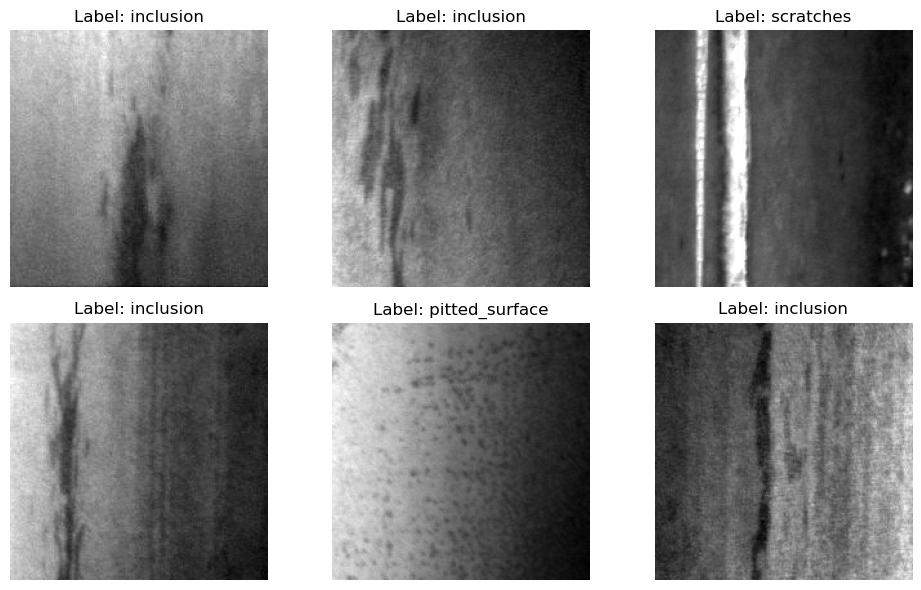

In [2]:
## Some random images showcase

import random 



plt.figure(figsize=(10, 6))

num_train_samples = X_train.shape[0]
random_indices = random.sample(range(num_train_samples), 6)


for i, idx in enumerate(random_indices):
    image = X_train[idx]
    label_id = y_train[idx]
    label_name = class_names[label_id] 

    plt.subplot(2, 3, i + 1) 
    plt.imshow(image.squeeze(), cmap='gray') 
    plt.title(f"Label: {label_name}")
    plt.axis('off')

plt.tight_layout() 
plt.show()

In [3]:
## Scaling data 

X_train_scaled = X_train.astype('float32') / 255.0
X_val_scaled = X_val.astype('float32') / 255.0
X_test_scaled = X_test.astype('float32') / 255.0

print(f"X_train_scaled shape: {X_train_scaled.shape}, dtype: {X_train_scaled.dtype}")
print(f"X_val_scaled shape: {X_val_scaled.shape}, dtype: {X_val_scaled.dtype}")
print(f"X_test_scaled shape: {X_test_scaled.shape}, dtype: {X_test_scaled.dtype}")


X_train_scaled shape: (1260, 200, 200, 1), dtype: float32
X_val_scaled shape: (270, 200, 200, 1), dtype: float32
X_test_scaled shape: (270, 200, 200, 1), dtype: float32


### <a id='toc2_2_'></a>[MLP Architecture Design](#toc0_)  

- Input layer, flattening: This is the critical first layer for an MLP processing image data. MLPs (Dense layers) expect a 1D input vector. This layer takes the 2D (or 3D for color images) image data (IMG_HEIGHT, IMG_WIDTH, 1) and flattens it into a single 1D vector (IMG_HEIGHT * IMG_WIDTH * 1). For  200x200 grayscale images, this results in 200 * 200 * 1 = 40,000 features per image.
- Hidden layers: 2 hidden layers with 512 and 256 neurons with relu activation function and after that a dropout to avoid overfitting.
- Output layer: The final classification layer.
units=num_classes: Must match the total number of distinct defect classes (6 in the NEU dataset).
activation='softmax': As explained before, softmax converts the raw outputs into a probability distribution over the 6 classes, which is essential for multi-class classification.


In [33]:
input_shape_img = (IMG_HEIGHT, IMG_WIDTH, 1)

mlp_image_model = models.Sequential([
    layers.Flatten(input_shape=input_shape_img, name='flatten_input'),

    layers.Dense(1024, name='dense_1'),
    layers.BatchNormalization(name='bn_1'),
    layers.Activation('relu', name='relu_1'),
    layers.Dropout(0.4, name='dropout_1'),

    layers.Dense(512, name='dense_2'),
    layers.BatchNormalization(name='bn_2'),
    layers.Activation('relu', name='relu_2'),
    layers.Dropout(0.4, name='dropout_2'),

    layers.Dense(256, name='dense_3'),
    layers.BatchNormalization(name='bn_3'),
    layers.Activation('relu', name='relu_3'),
    layers.Dropout(0.3, name='dropout_3'),

    layers.Dense(128, name='dense_4'),
    layers.BatchNormalization(name='bn_4'),
    layers.Activation('relu', name='relu_4'),
    layers.Dropout(0.3, name='dropout_4'),

    layers.Dense(num_classes, activation='softmax', name='output_layer')
])

learning_rate_mlp_image = 0.0005  # slightly lower LR helps deep MLPs
adam_optimizer_mlp_image = tf.keras.optimizers.Adam(learning_rate=learning_rate_mlp_image)

mlp_image_model.compile(optimizer=adam_optimizer_mlp_image,
                        loss='sparse_categorical_crossentropy',
                        metrics=['accuracy'])

mlp_image_model.summary()


Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_input (Flatten)     (None, 40000)             0         
                                                                 
 dense_1 (Dense)             (None, 1024)              40961024  
                                                                 
 bn_1 (BatchNormalization)   (None, 1024)              4096      
                                                                 
 relu_1 (Activation)         (None, 1024)              0         
                                                                 
 dropout_1 (Dropout)         (None, 1024)              0         
                                                                 
 dense_2 (Dense)             (None, 512)               524800    
                                                                 
 bn_2 (BatchNormalization)   (None, 512)              

In [34]:
epochs = 20
batch_size = 32 

history_mlp_image = mlp_image_model.fit(
    X_train_scaled, y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val_scaled, y_val),
    verbose=1 
)

Epoch 1/20
40/40 [==============================] - 16s 356ms/step - loss: 1.7615 - accuracy: 0.3222 - val_loss: 12.0486 - val_accuracy: 0.1741
Epoch 2/20
40/40 [==============================] - 14s 358ms/step - loss: 1.4993 - accuracy: 0.4183 - val_loss: 7.5966 - val_accuracy: 0.2148
Epoch 3/20
40/40 [==============================] - 14s 353ms/step - loss: 1.3915 - accuracy: 0.4603 - val_loss: 3.8049 - val_accuracy: 0.2667
Epoch 4/20
40/40 [==============================] - 14s 349ms/step - loss: 1.2796 - accuracy: 0.4929 - val_loss: 2.5532 - val_accuracy: 0.3481
Epoch 5/20
40/40 [==============================] - 14s 350ms/step - loss: 1.2360 - accuracy: 0.5302 - val_loss: 3.1237 - val_accuracy: 0.3630
Epoch 6/20
40/40 [==============================] - 14s 351ms/step - loss: 1.1694 - accuracy: 0.5484 - val_loss: 5.3009 - val_accuracy: 0.2185
Epoch 7/20
40/40 [==============================] - 14s 350ms/step - loss: 1.1089 - accuracy: 0.5516 - val_loss: 3.1705 - val_accuracy: 0.314

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be rem

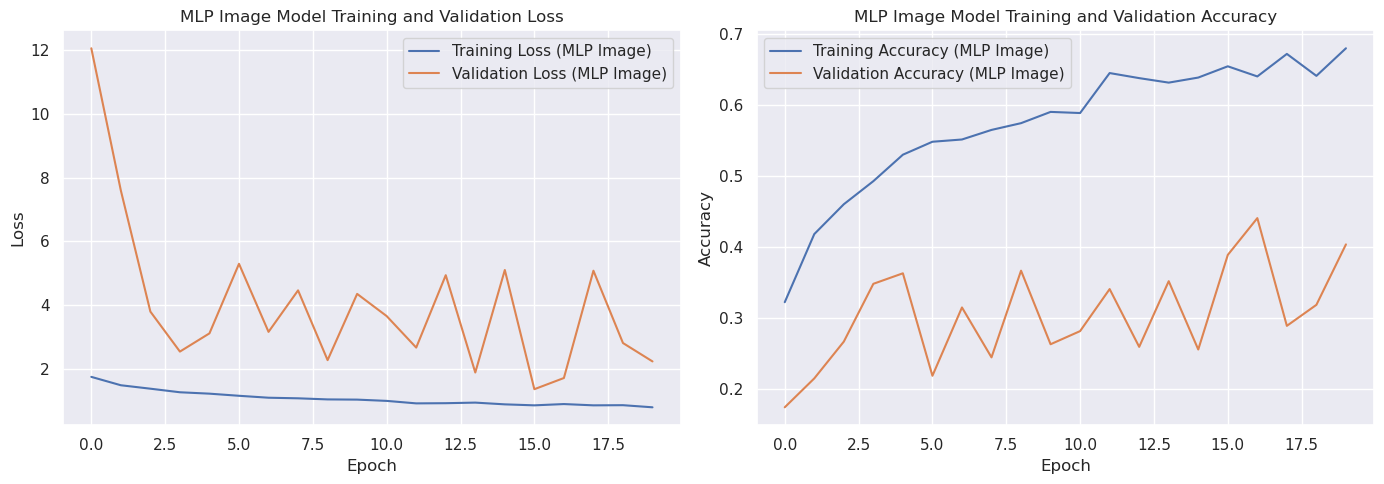

In [35]:
## Plot acc and loss

epochs_range = range(epochs)

train_loss_mlp_image = history_mlp_image.history['loss']
val_loss_mlp_image = history_mlp_image.history['val_loss']
train_accuracy_mlp_image = history_mlp_image.history['accuracy']
val_accuracy_mlp_image = history_mlp_image.history['val_accuracy']

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1) 
sns.lineplot(x=epochs_range, y=train_loss_mlp_image, label='Training Loss (MLP Image)')
sns.lineplot(x=epochs_range, y=val_loss_mlp_image, label='Validation Loss (MLP Image)')
plt.title('MLP Image Model Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
sns.lineplot(x=epochs_range, y=train_accuracy_mlp_image, label='Training Accuracy (MLP Image)')
sns.lineplot(x=epochs_range, y=val_accuracy_mlp_image, label='Validation Accuracy (MLP Image)')
plt.title('MLP Image Model Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout() 


In [36]:
## Evaluation on test data
test_loss_mlp_image, test_accuracy_mlp_image = mlp_image_model.evaluate(X_test_scaled, y_test, verbose=0)

print(f"\nMLP Image Model Test Loss: {test_loss_mlp_image:.4f}")
print(f"MLP Image Model Test Accuracy: {test_accuracy_mlp_image:.4f}")


y_pred_probs_mlp_image = mlp_image_model.predict(X_test_scaled, verbose=0)

y_pred_mlp_image = np.argmax(y_pred_probs_mlp_image, axis=1)


print(classification_report(y_test, y_pred_mlp_image, target_names=class_names))

print(f"\nMLP Image Model Overall Test Accuracy (from sklearn): {accuracy_score(y_test, y_pred_mlp_image):.4f}")
print(f"MLP Image Model Weighted Precision: {precision_score(y_test, y_pred_mlp_image, average='weighted'):.4f}")
print(f"MLP Image Model Weighted Recall: {recall_score(y_test, y_pred_mlp_image, average='weighted'):.4f}")
print(f"MLP Image Model Weighted F1-Score: {f1_score(y_test, y_pred_mlp_image, average='weighted'):.4f}")


MLP Image Model Test Loss: 2.6033
MLP Image Model Test Accuracy: 0.3926
                 precision    recall  f1-score   support

        crazing       0.00      0.00      0.00        45
      inclusion       0.60      0.07      0.12        45
        patches       0.30      0.91      0.45        45
 pitted_surface       0.71      0.64      0.67        45
rolled-in_scale       0.00      0.00      0.00        45
      scratches       0.38      0.73      0.50        45

       accuracy                           0.39       270
      macro avg       0.33      0.39      0.29       270
   weighted avg       0.33      0.39      0.29       270


MLP Image Model Overall Test Accuracy (from sklearn): 0.3926
MLP Image Model Weighted Precision: 0.3310
MLP Image Model Weighted Recall: 0.3926
MLP Image Model Weighted F1-Score: 0.2908


/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", le


--- Raw MLP Image Model Confusion Matrix (counts) ---
[[ 0  0 40  3  0  2]
 [ 0  3  3  7  0 32]
 [ 0  0 41  2  0  2]
 [ 0  0  9 29  0  7]
 [ 0  2 32  0  0 11]
 [ 0  0 12  0  0 33]]


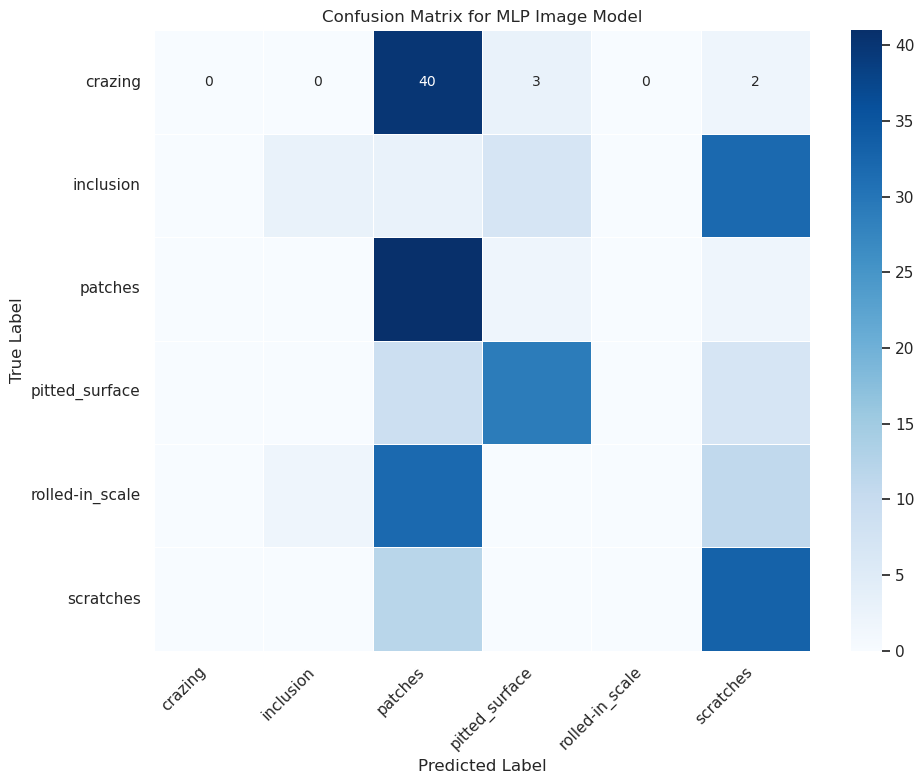

In [37]:

cm_mlp_image = confusion_matrix(y_test, y_pred_mlp_image)

print("\n--- Raw MLP Image Model Confusion Matrix (counts) ---")
print(cm_mlp_image)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_mlp_image,
            annot=True,       
            fmt='d',           
            cmap='Blues',      
            xticklabels=class_names, 
            yticklabels=class_names, 
            linewidths=.5,    
            cbar=True,        
            annot_kws={"size": 10})

plt.title('Confusion Matrix for MLP Image Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


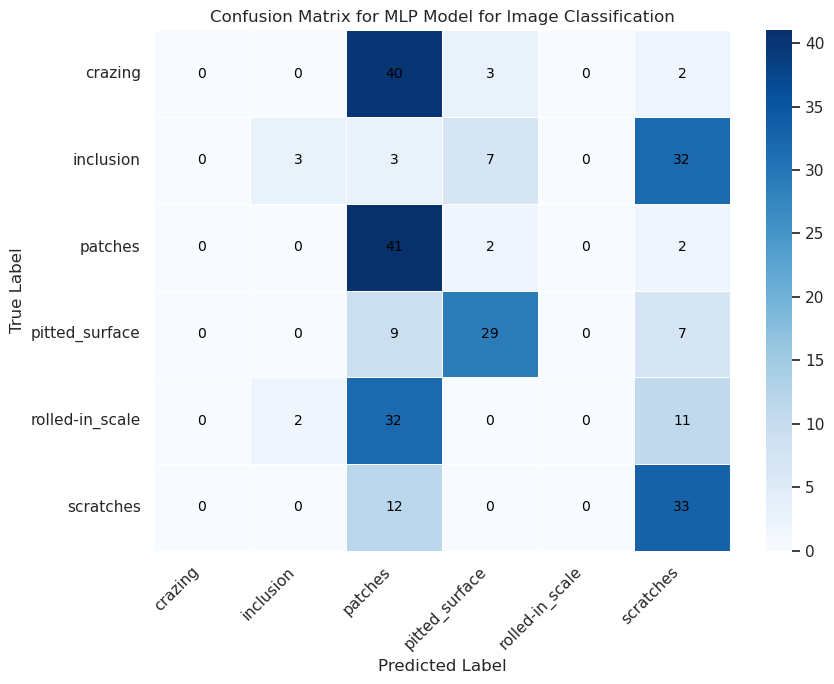

In [39]:
plt.figure(figsize=(9, 7))
ax = sns.heatmap(cm_mlp_image,
                 annot=False,
                 cmap='Blues',
                 xticklabels=class_names,
                 yticklabels=class_names,
                 linewidths=.5,
                 cbar=True)

# Manually annotate each cell
for i in range(cm_mlp_image.shape[0]):
    for j in range(cm_mlp_image.shape[1]):
        text = ax.text(j + 0.5, i + 0.5, str(cm_mlp_image[i, j]),
                       ha='center', va='center',
                       color='black', fontsize=10)

plt.title('Confusion Matrix for MLP Model for Image Classification')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### <a id='toc2_3_'></a>[CNN Architecture Design](#toc0_)  

In [4]:
DATA_DIR = "NEU-DET"
IMG_HEIGHT, IMG_WIDTH = 200, 200 
SEED = 42

# === Step 2: Load Images ===
def load_images_from_directory(image_dir):
    image_paths = []
    labels = []
    class_names = sorted(os.listdir(image_dir))
    class_indices = {name: idx for idx, name in enumerate(class_names)}

    for label in class_names:
        class_folder = os.path.join(image_dir, label)
        for file in os.listdir(class_folder):
            if file.lower().endswith((".jpg", ".png", ".jpeg")):
                image_paths.append(os.path.join(class_folder, file))
                labels.append(class_indices[label])

    return image_paths, labels, class_names

In [5]:
train_image_dir = os.path.join(DATA_DIR, "train", "images")
val_image_dir = os.path.join(DATA_DIR, "validation", "images")

train_paths, train_labels, class_names = load_images_from_directory(train_image_dir)
val_paths, val_labels, _ = load_images_from_directory(val_image_dir)

all_paths = np.array(train_paths + val_paths)
all_labels = np.array(train_labels + val_labels)

In [6]:
def preprocess_images(image_paths):
    images = []
    for path in image_paths:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT))
        images.append(img)
    return np.array(images, dtype=np.float32)

all_images = preprocess_images(all_paths)
all_images = all_images[..., np.newaxis]  

scaler = MinMaxScaler()
N = all_images.shape[0]
all_images_reshaped = all_images.reshape(N, -1)
all_images_scaled = scaler.fit_transform(all_images_reshaped).reshape(N, IMG_HEIGHT, IMG_WIDTH, 1)

In [7]:
## Split images into train test and validation

X_temp, X_test, y_temp, y_test = train_test_split(all_images_scaled, all_labels, test_size=0.15, random_state=SEED, stratify=all_labels)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.15, random_state=SEED, stratify=y_temp)

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

Train: (1300, 200, 200, 1), Val: (230, 200, 200, 1), Test: (270, 200, 200, 1)


In [6]:
## CNN model

input_shape_img = (IMG_HEIGHT, IMG_WIDTH, 1)
num_classes = len(class_names)

cnn_image_model_1 = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='linear', padding='same', input_shape=input_shape_img),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation='linear', padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3, 3), activation='linear', padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation='linear'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(0.5),

    layers.Dense(num_classes, activation='softmax')
])

cnn_image_model_1.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn_image_model_1.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 200, 200, 32)      320       
                                                                 
 batch_normalization (BatchN  (None, 200, 200, 32)     128       
 ormalization)                                                   
                                                                 
 activation (Activation)     (None, 200, 200, 32)      0         
                                                                 
 max_pooling2d (MaxPooling2D  (None, 100, 100, 32)     0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 100, 100, 32)      0         
                                                                 
 conv2d_1 (Conv2D)           (None, 100, 100, 64)      1

In [7]:
history_cnn_1 = cnn_image_model_1.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=1
)

Epoch 1/20
41/41 [==============================] - 58s 1s/step - loss: 1.0930 - accuracy: 0.6008 - val_loss: 2.5462 - val_accuracy: 0.1652
Epoch 2/20
41/41 [==============================] - 49s 1s/step - loss: 0.6450 - accuracy: 0.7469 - val_loss: 3.1178 - val_accuracy: 0.1652
Epoch 3/20
41/41 [==============================] - 54s 1s/step - loss: 0.5494 - accuracy: 0.7931 - val_loss: 3.6346 - val_accuracy: 0.1652
Epoch 4/20
41/41 [==============================] - 56s 1s/step - loss: 0.4615 - accuracy: 0.8246 - val_loss: 4.1796 - val_accuracy: 0.1652
Epoch 5/20
41/41 [==============================] - 56s 1s/step - loss: 0.4288 - accuracy: 0.8369 - val_loss: 4.3006 - val_accuracy: 0.1652
Epoch 6/20
41/41 [==============================] - 55s 1s/step - loss: 0.3634 - accuracy: 0.8738 - val_loss: 5.1312 - val_accuracy: 0.1652
Epoch 7/20
41/41 [==============================] - 55s 1s/step - loss: 0.3507 - accuracy: 0.8723 - val_loss: 4.6282 - val_accuracy: 0.1870
Epoch 8/20
41/41 [==

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be rem

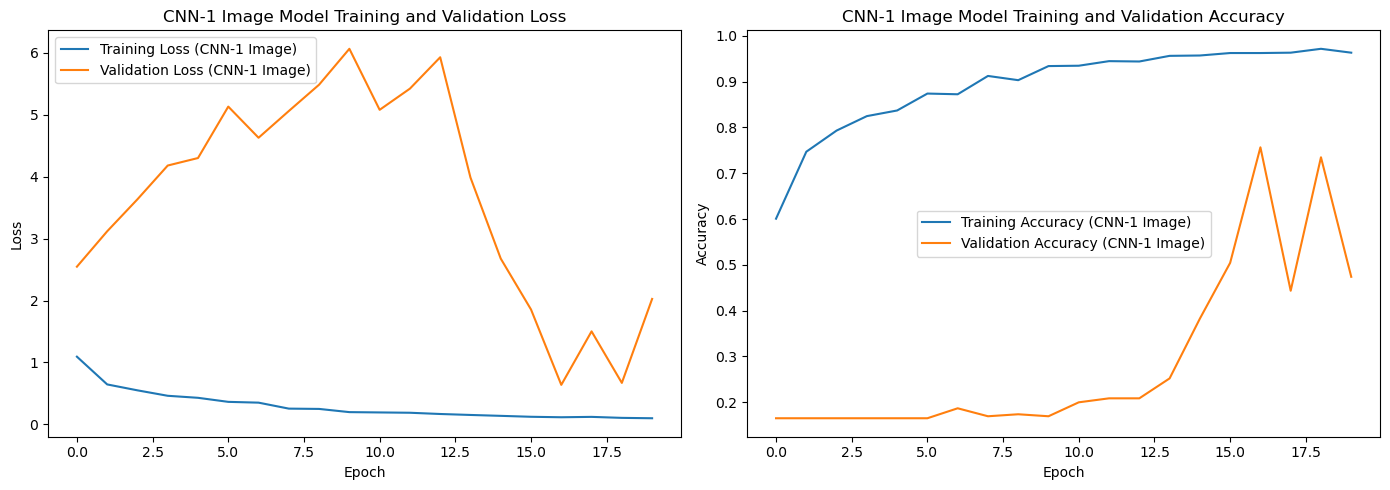

In [10]:
## Plot acc and loss

epochs_range = range(20)

train_loss_mlp_image = history_cnn_1.history['loss']
val_loss_mlp_image = history_cnn_1.history['val_loss']
train_accuracy_mlp_image = history_cnn_1.history['accuracy']
val_accuracy_mlp_image = history_cnn_1.history['val_accuracy']

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1) 
sns.lineplot(x=epochs_range, y=train_loss_mlp_image, label='Training Loss (CNN-1 Image)')
sns.lineplot(x=epochs_range, y=val_loss_mlp_image, label='Validation Loss (CNN-1 Image)')
plt.title('CNN-1 Image Model Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
sns.lineplot(x=epochs_range, y=train_accuracy_mlp_image, label='Training Accuracy (CNN-1 Image)')
sns.lineplot(x=epochs_range, y=val_accuracy_mlp_image, label='Validation Accuracy (CNN-1 Image)')
plt.title('CNN-1 Image Model Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout() 

In [11]:
## Evaluation on test data
test_loss_cnn_1_image, test_accuracy_cnn_1_image = cnn_image_model_1.evaluate(X_test, y_test, verbose=0)

print(f"\nCNN-1 Image Model Test Loss: {test_loss_cnn_1_image:.4f}")
print(f"CNN-1 Image Model Test Accuracy: {test_accuracy_cnn_1_image:.4f}")


y_pred_probs_cnn_1_image = cnn_image_model_1.predict(X_test, verbose=0)

y_pred_cnn_1_image = np.argmax(y_pred_probs_cnn_1_image, axis=1)


print(classification_report(y_test, y_pred_cnn_1_image, target_names=class_names))

print(f"\nCNN-1 Image Model Overall Test Accuracy (from sklearn): {accuracy_score(y_test, y_pred_cnn_1_image):.4f}")
print(f"CNN-1 Image Model Weighted Precision: {precision_score(y_test, y_pred_cnn_1_image, average='weighted'):.4f}")
print(f"CNN-1 Image Model Weighted Recall: {recall_score(y_test, y_pred_cnn_1_image, average='weighted'):.4f}")
print(f"CNN-1 Image Model Weighted F1-Score: {f1_score(y_test, y_pred_cnn_1_image, average='weighted'):.4f}")


CNN-1 Image Model Test Loss: 1.8384
CNN-1 Image Model Test Accuracy: 0.5407
                 precision    recall  f1-score   support

        crazing       0.00      0.00      0.00        45
      inclusion       0.55      1.00      0.71        45
        patches       1.00      0.07      0.12        45
 pitted_surface       0.77      0.44      0.56        45
rolled-in_scale       0.36      1.00      0.53        45
      scratches       0.97      0.73      0.84        45

       accuracy                           0.54       270
      macro avg       0.61      0.54      0.46       270
   weighted avg       0.61      0.54      0.46       270


CNN-1 Image Model Overall Test Accuracy (from sklearn): 0.5407
CNN-1 Image Model Weighted Precision: 0.6081
CNN-1 Image Model Weighted Recall: 0.5407
CNN-1 Image Model Weighted F1-Score: 0.4603


/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", le


--- Raw CNN-1 Image Model Confusion Matrix (counts) ---
[[ 0  0  0  0 45  0]
 [ 0 45  0  0  0  0]
 [ 0  0  3  6 35  1]
 [ 0 25  0 20  0  0]
 [ 0  0  0  0 45  0]
 [ 0 12  0  0  0 33]]


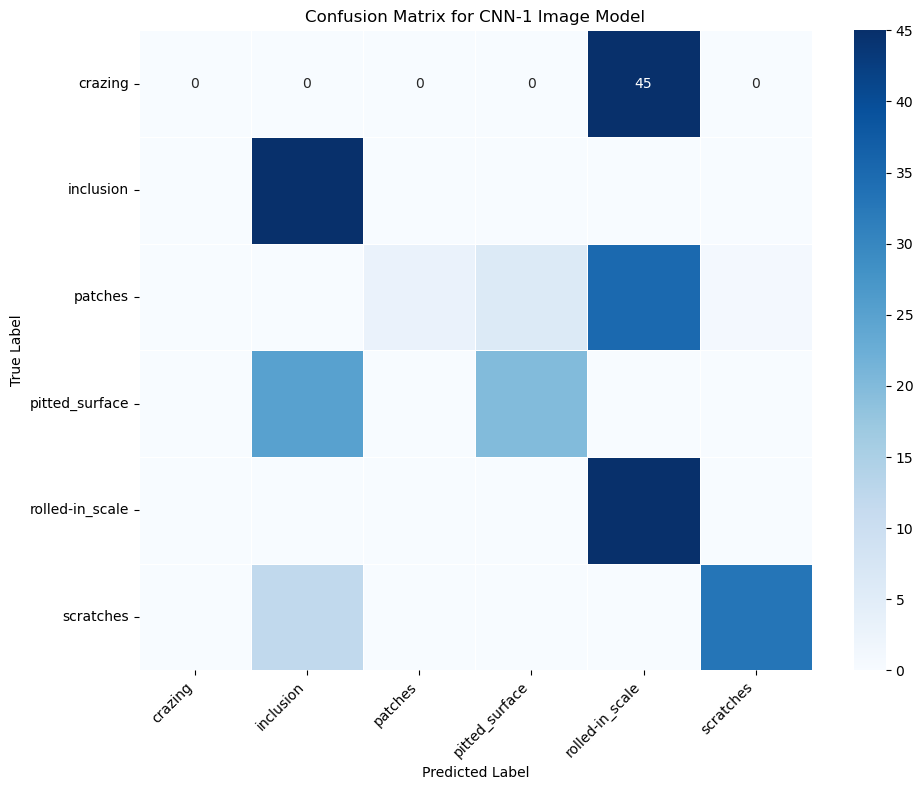

In [13]:
from sklearn.metrics import confusion_matrix

cm_cnn_1_image = confusion_matrix(y_test, y_pred_cnn_1_image)

print("\n--- Raw CNN-1 Image Model Confusion Matrix (counts) ---")
print(cm_cnn_1_image)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_cnn_1_image,
            annot=True,       
            fmt='d',           
            cmap='Blues',      
            xticklabels=class_names, 
            yticklabels=class_names, 
            linewidths=.5,    
            cbar=True,        
            annot_kws={"size": 10})

plt.title('Confusion Matrix for CNN-1 Image Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


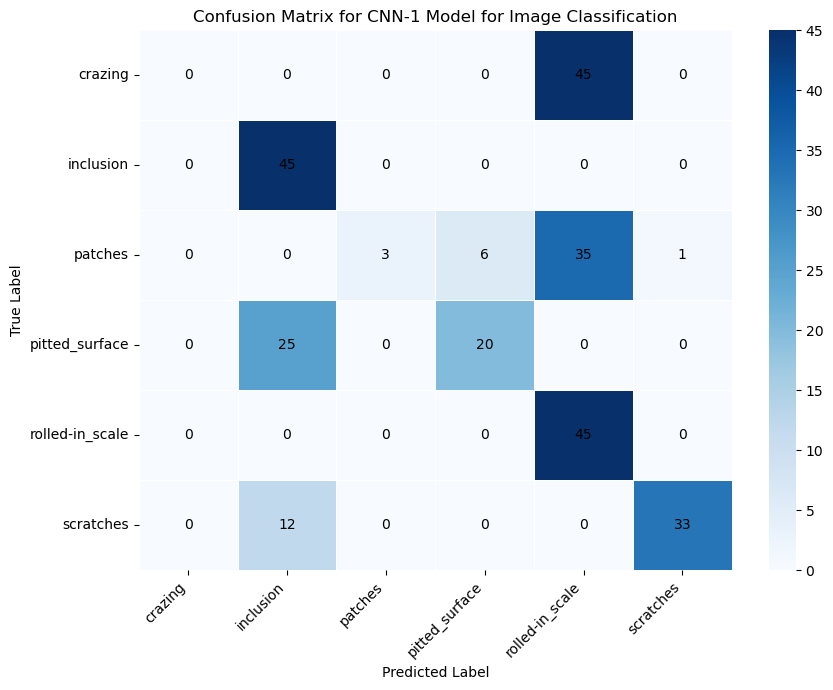

In [14]:
plt.figure(figsize=(9, 7))
ax = sns.heatmap(cm_cnn_1_image,
                 annot=False,
                 cmap='Blues',
                 xticklabels=class_names,
                 yticklabels=class_names,
                 linewidths=.5,
                 cbar=True)

# Manually annotate each cell
for i in range(cm_cnn_1_image.shape[0]):
    for j in range(cm_cnn_1_image.shape[1]):
        text = ax.text(j + 0.5, i + 0.5, str(cm_cnn_1_image[i, j]),
                       ha='center', va='center',
                       color='black', fontsize=10)

plt.title('Confusion Matrix for CNN-1 Model for Image Classification')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### <a id='toc2_4_'></a>[Fine-Tuned CNN Architecture Design](#toc0_)  

In [2]:
## Data loading and preprocessing
import random

np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

DATA_DIR = "NEU-DET"
TRAIN_DIR = os.path.join(DATA_DIR, "train", "images")
VAL_DIR = os.path.join(DATA_DIR, "validation", "images")
IMG_HEIGHT, IMG_WIDTH = 200, 200
SEED = 42


def load_images_from_directory(image_dir):
    """Load images and labels from directory structure"""
    image_paths = []
    labels = []
    class_names = sorted(os.listdir(image_dir))
    class_indices = {name: idx for idx, name in enumerate(class_names)}
    
    print(f"Found classes: {class_names}")
    
    for label in class_names:
        class_folder = os.path.join(image_dir, label)
        class_files = [f for f in os.listdir(class_folder) 
                      if f.lower().endswith((".jpg", ".png", ".jpeg"))]
        print(f"Class '{label}': {len(class_files)} images")
        
        for file in class_files:
            image_paths.append(os.path.join(class_folder, file))
            labels.append(class_indices[label])
    
    return image_paths, labels, class_names

def preprocess_images(image_paths):
    """Load and resize images"""
    images = []
    for i, path in enumerate(image_paths):
        if i % 100 == 0:
            print(f"Processing image {i+1}/{len(image_paths)}")
        
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is not None:
            img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT))
            images.append(img)
        else:
            print(f"Warning: Could not load image {path}")
    
    return np.array(images, dtype=np.float32)

train_paths, train_labels, class_names = load_images_from_directory(TRAIN_DIR)
train_images = preprocess_images(train_paths)

# Load validation data
print("\nLoading validation data...")
val_paths, val_labels, _ = load_images_from_directory(VAL_DIR)
val_images = preprocess_images(val_paths)

# Add channel dimension
train_images = train_images[..., np.newaxis]  
val_images = val_images[..., np.newaxis]

# Convert labels to numpy arrays
train_labels = np.array(train_labels)
val_labels = np.array(val_labels)

print(f"\nTrain images shape: {train_images.shape}")
print(f"Validation images shape: {val_images.shape}")
print(f"Number of classes: {len(class_names)}")



Found classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Class 'crazing': 240 images
Class 'inclusion': 240 images
Class 'patches': 240 images
Class 'pitted_surface': 240 images
Class 'rolled-in_scale': 240 images
Class 'scratches': 240 images
Processing image 1/1440
Processing image 101/1440
Processing image 201/1440
Processing image 301/1440
Processing image 401/1440
Processing image 501/1440
Processing image 601/1440
Processing image 701/1440
Processing image 801/1440
Processing image 901/1440
Processing image 1001/1440
Processing image 1101/1440
Processing image 1201/1440
Processing image 1301/1440
Processing image 1401/1440

Loading validation data...
Found classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Class 'crazing': 60 images
Class 'inclusion': 60 images
Class 'patches': 60 images
Class 'pitted_surface': 60 images
Class 'rolled-in_scale': 60 images
Class 'scratches': 60 images
Processin

In [3]:
## Normalize images and perform data augmentation

from tensorflow.keras.preprocessing.image import ImageDataGenerator


def normalize_images(images):
    """Normalize images to [0, 1] range"""
    return images / 255.0

train_images_normalized = normalize_images(train_images)
val_images_normalized = normalize_images(val_images)

print("Images normalized to [0, 1] range")

train_datagen = ImageDataGenerator(
    rotation_range=20,           
    width_shift_range=0.1,      
    height_shift_range=0.1,      
    shear_range=0.1,            
    zoom_range=0.1,             
    horizontal_flip=True,       
    fill_mode='nearest'         
)

val_datagen = ImageDataGenerator()

train_datagen.fit(train_images_normalized)

print("Data augmentation generator created")

def show_augmented_images(images, labels, class_names, datagen, num_examples=6):
    """Display original and augmented versions of images"""
    fig, axes = plt.subplots(num_examples, 5, figsize=(15, num_examples * 3))
    
    for i in range(num_examples):
        idx = random.randint(0, len(images) - 1)
        img = images[idx:idx+1]  
        label = labels[idx]
        
        axes[i, 0].imshow(img[0, :, :, 0], cmap='gray')
        axes[i, 0].set_title(f'Original\nClass: {class_names[label]}')
        axes[i, 0].axis('off')
        
        aug_iter = datagen.flow(img, batch_size=1)
        for j in range(1, 5):
            aug_img = next(aug_iter)[0]
            axes[i, j].imshow(aug_img[:, :, 0], cmap='gray')
            axes[i, j].set_title(f'Augmented {j}')
            axes[i, j].axis('off')
    
    plt.tight_layout()
    plt.show()

Images normalized to [0, 1] range
Data augmentation generator created


Displaying augmented image examples...


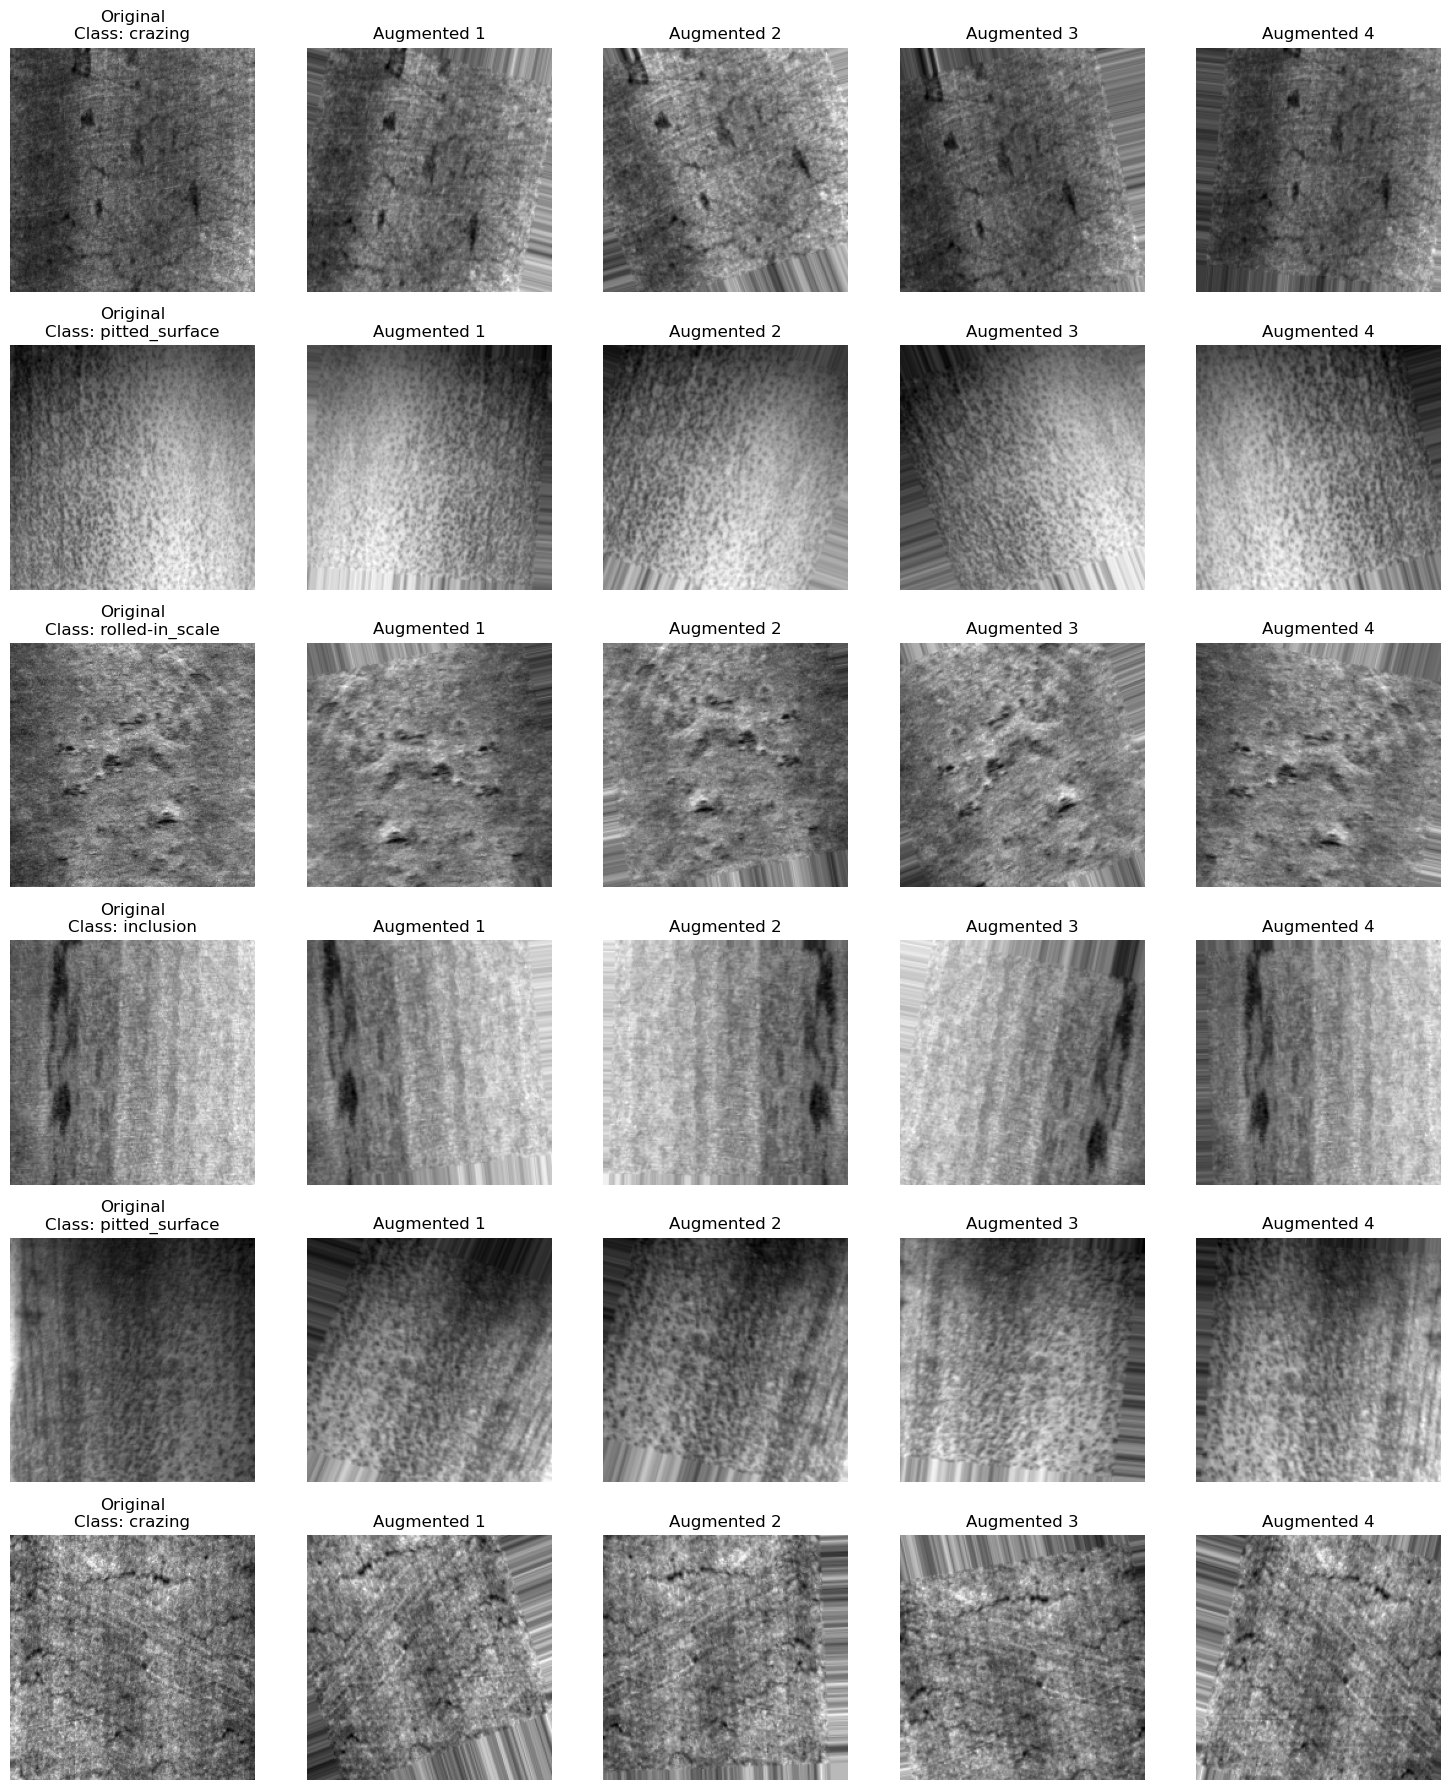

In [12]:
# Show examples of augmented images
print("Displaying augmented image examples...")
show_augmented_images(train_images_normalized, train_labels, class_names, train_datagen)


In [20]:
## Fine-tune CNN Architecture based on criterias


def create_modified_cnn(input_shape, num_classes):
    model = models.Sequential([
        layers.SeparableConv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.2),  
        
        layers.SeparableConv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),  
        
        layers.SeparableConv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),  
        
        layers.GlobalAveragePooling2D(),
        
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        
        # Output layer
        layers.Dense(num_classes, activation='softmax')
    ])
    
    return model

In [21]:
# Create the model
input_shape = (IMG_HEIGHT, IMG_WIDTH, 1)
num_classes = len(class_names)

model = create_modified_cnn(input_shape, num_classes)

model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 separable_conv2d (Separable  (None, 200, 200, 32)     73        
 Conv2D)                                                         
                                                                 
 batch_normalization_4 (Batc  (None, 200, 200, 32)     128       
 hNormalization)                                                 
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 100, 100, 32)     0         
 2D)                                                             
                                                                 
 dropout_4 (Dropout)         (None, 100, 100, 32)      0         
                                                                 
 separable_conv2d_1 (Separab  (None, 100, 100, 64)     2400      
 leConv2D)                                            

In [22]:
## Train the model


BATCH_SIZE = 32
EPOCHS = 20

train_generator = train_datagen.flow(
    train_images_normalized, 
    train_labels,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_generator = val_datagen.flow(
    val_images_normalized,
    val_labels,
    batch_size=BATCH_SIZE,
    shuffle=False
)

steps_per_epoch = len(train_images_normalized) // BATCH_SIZE
validation_steps = len(val_images_normalized) // BATCH_SIZE


history = model.fit(
    train_generator,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=val_generator,
    validation_steps=validation_steps,
    verbose=1
)

Epoch 1/20
45/45 [==============================] - 47s 1s/step - loss: 1.3388 - accuracy: 0.4938 - val_loss: 1.7964 - val_accuracy: 0.1705
Epoch 2/20
45/45 [==============================] - 44s 969ms/step - loss: 1.0557 - accuracy: 0.6500 - val_loss: 1.8165 - val_accuracy: 0.1705
Epoch 3/20
45/45 [==============================] - 43s 958ms/step - loss: 0.8846 - accuracy: 0.7035 - val_loss: 1.8960 - val_accuracy: 0.1705
Epoch 4/20
45/45 [==============================] - 44s 979ms/step - loss: 0.7350 - accuracy: 0.7708 - val_loss: 2.0652 - val_accuracy: 0.1705
Epoch 5/20
45/45 [==============================] - 44s 981ms/step - loss: 0.5901 - accuracy: 0.8194 - val_loss: 2.3204 - val_accuracy: 0.1506
Epoch 6/20
45/45 [==============================] - 46s 999ms/step - loss: 0.5293 - accuracy: 0.8222 - val_loss: 2.6092 - val_accuracy: 0.1705
Epoch 7/20
45/45 [==============================] - 43s 958ms/step - loss: 0.4777 - accuracy: 0.8403 - val_loss: 3.0133 - val_accuracy: 0.1705
Ep

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be rem

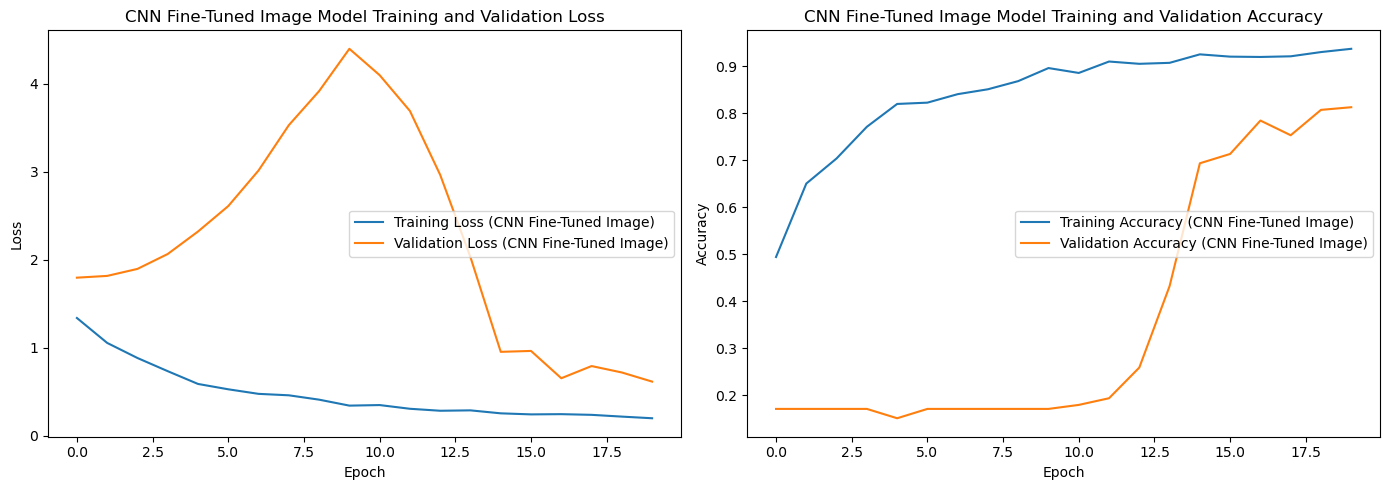

In [23]:
## Plot acc and loss

epochs_range = range(20)

train_loss_cnn_2_image = history.history['loss']
val_loss_cnn_2_image = history.history['val_loss']
train_accuracy_cnn_2_image = history.history['accuracy']
val_accuracy_cnn_2_image = history.history['val_accuracy']

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1) 
sns.lineplot(x=epochs_range, y=train_loss_cnn_2_image, label='Training Loss (CNN Fine-Tuned Image)')
sns.lineplot(x=epochs_range, y=val_loss_cnn_2_image, label='Validation Loss (CNN Fine-Tuned Image)')
plt.title('CNN Fine-Tuned Image Model Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
sns.lineplot(x=epochs_range, y=train_accuracy_cnn_2_image, label='Training Accuracy (CNN Fine-Tuned Image)')
sns.lineplot(x=epochs_range, y=val_accuracy_cnn_2_image, label='Validation Accuracy (CNN Fine-Tuned Image)')
plt.title('CNN Fine-Tuned Image Model Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout() 

In [24]:
## Evaluation on test data
test_loss_cnn_2_image, test_accuracy_cnn_2_image = model.evaluate(X_test, y_test, verbose=0)

print(f"\nCNN Fine-Tuned Image Model Test Loss: {test_loss_cnn_2_image:.4f}")
print(f"CNN Fine-Tuned Image Model Test Accuracy: {test_accuracy_cnn_2_image:.4f}")


y_pred_probs_cnn_2_image = model.predict(X_test, verbose=0)

y_pred_cnn_2_image = np.argmax(y_pred_probs_cnn_2_image, axis=1)


print(classification_report(y_test, y_pred_cnn_2_image, target_names=class_names))

print(f"\nCNN Fine-Tuned  Image Model Overall Test Accuracy (from sklearn): {accuracy_score(y_test, y_pred_cnn_2_image):.4f}")
print(f"CNN Fine-Tuned Image Model Weighted Precision: {precision_score(y_test, y_pred_cnn_2_image, average='weighted'):.4f}")
print(f"CNN Fine-Tuned Image Model Weighted Recall: {recall_score(y_test, y_pred_cnn_2_image, average='weighted'):.4f}")
print(f"CNN Fine-Tuned Image Model Weighted F1-Score: {f1_score(y_test, y_pred_cnn_2_image, average='weighted'):.4f}")


CNN Fine-Tuned Image Model Test Loss: 0.5071
CNN Fine-Tuned Image Model Test Accuracy: 0.8407
                 precision    recall  f1-score   support

        crazing       0.80      1.00      0.89        45
      inclusion       0.81      0.87      0.84        45
        patches       1.00      0.80      0.89        45
 pitted_surface       1.00      0.51      0.68        45
rolled-in_scale       0.85      1.00      0.92        45
      scratches       0.72      0.87      0.79        45

       accuracy                           0.84       270
      macro avg       0.86      0.84      0.83       270
   weighted avg       0.86      0.84      0.83       270


CNN Fine-Tuned  Image Model Overall Test Accuracy (from sklearn): 0.8407
CNN Fine-Tuned Image Model Weighted Precision: 0.8646
CNN Fine-Tuned Image Model Weighted Recall: 0.8407
CNN Fine-Tuned Image Model Weighted F1-Score: 0.8336



--- Raw CNN Fine-Tuned Image Model Confusion Matrix (counts) ---
[[45  0  0  0  0  0]
 [ 0 39  0  0  0  6]
 [ 9  0 36  0  0  0]
 [ 2  6  0 23  5  9]
 [ 0  0  0  0 45  0]
 [ 0  3  0  0  3 39]]


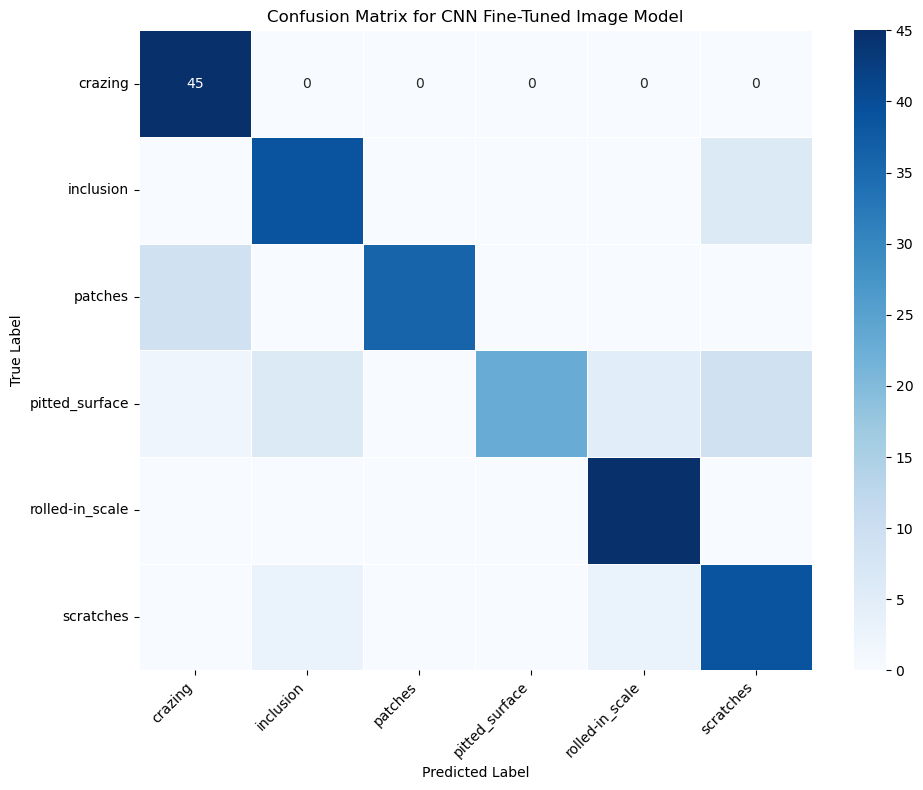

In [25]:

cm_cnn_2_image = confusion_matrix(y_test, y_pred_cnn_2_image)

print("\n--- Raw CNN Fine-Tuned Image Model Confusion Matrix (counts) ---")
print(cm_cnn_2_image)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_cnn_2_image,
            annot=True,       
            fmt='d',           
            cmap='Blues',      
            xticklabels=class_names, 
            yticklabels=class_names, 
            linewidths=.5,    
            cbar=True,        
            annot_kws={"size": 10})

plt.title('Confusion Matrix for CNN Fine-Tuned Image Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


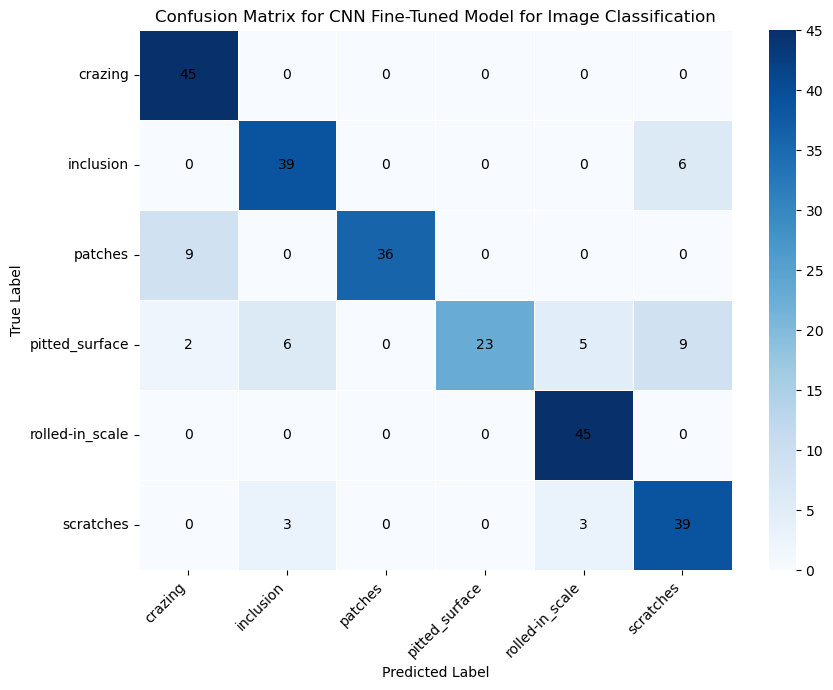

In [26]:
plt.figure(figsize=(9, 7))
ax = sns.heatmap(cm_cnn_2_image,
                 annot=False,
                 cmap='Blues',
                 xticklabels=class_names,
                 yticklabels=class_names,
                 linewidths=.5,
                 cbar=True)

# Manually annotate each cell
for i in range(cm_cnn_2_image.shape[0]):
    for j in range(cm_cnn_2_image.shape[1]):
        text = ax.text(j + 0.5, i + 0.5, str(cm_cnn_2_image[i, j]),
                       ha='center', va='center',
                       color='black', fontsize=10)

plt.title('Confusion Matrix for CNN Fine-Tuned Model for Image Classification')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### <a id='toc2_5_'></a>[Res-Net-50 Model](#toc0_)  

In [51]:
from tensorflow.keras.applications import ResNet50V2


In [52]:
train_images_rgb = np.repeat(train_images_normalized, 3, axis=-1)
val_images_rgb = np.repeat(val_images_normalized, 3, axis=-1)

print(f"Train RGB shape: {train_images_rgb.shape}") 
print(f"Val RGB shape: {val_images_rgb.shape}")

# Step 2: Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical
num_classes = len(class_names)
train_labels_cat = to_categorical(train_labels, num_classes=num_classes)
val_labels_cat = to_categorical(val_labels, num_classes=num_classes)

Train RGB shape: (1440, 200, 200, 3)
Val RGB shape: (360, 200, 200, 3)


In [56]:
resnet_weights_path = 'resnet50v2_weights_tf_dim_ordering_tf_kernels_notop.h5' 

base_model = ResNet50V2(
    input_shape=(200, 200, 3),
    include_top=False,
    weights=None  
)
base_model.load_weights(resnet_weights_path)

base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax') 
])

optimizer = optimizers.Adam(learning_rate=0.001)
model.compile(
    optimizer=optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resnet50v2 (Functional)     (None, 7, 7, 2048)        23564800  
                                                                 
 global_average_pooling2d_3   (None, 2048)             0         
 (GlobalAveragePooling2D)                                        
                                                                 
 dense_19 (Dense)            (None, 512)               1049088   
                                                                 
 dropout_18 (Dropout)        (None, 512)               0         
                                                                 
 dense_20 (Dense)            (None, 256)               131328    
                                                                 
 dropout_19 (Dropout)        (None, 256)               0         
                                                      

In [57]:
history = model.fit(
    train_images_rgb, train_labels_cat,
    epochs=5,
    batch_size=32,
    validation_data=(val_images_rgb, val_labels_cat),
    verbose=1)

Epoch 1/5


2025-05-28 17:00:58.246323: W tensorflow/tsl/framework/cpu_allocator_impl.cc:82] Allocation of 691200000 exceeds 10% of free system memory.


45/45 [==============================] - 74s 2s/step - loss: 0.3403 - accuracy: 0.8840 - val_loss: 0.0674 - val_accuracy: 0.9861
Epoch 2/5
45/45 [==============================] - 66s 1s/step - loss: 0.0425 - accuracy: 0.9847 - val_loss: 0.0415 - val_accuracy: 0.9889
Epoch 3/5
45/45 [==============================] - 67s 1s/step - loss: 0.0225 - accuracy: 0.9917 - val_loss: 0.0741 - val_accuracy: 0.9694
Epoch 4/5
45/45 [==============================] - 68s 2s/step - loss: 0.0178 - accuracy: 0.9958 - val_loss: 0.0710 - val_accuracy: 0.9806
Epoch 5/5
45/45 [==============================] - 66s 1s/step - loss: 0.0257 - accuracy: 0.9944 - val_loss: 0.0868 - val_accuracy: 0.9806


/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be rem

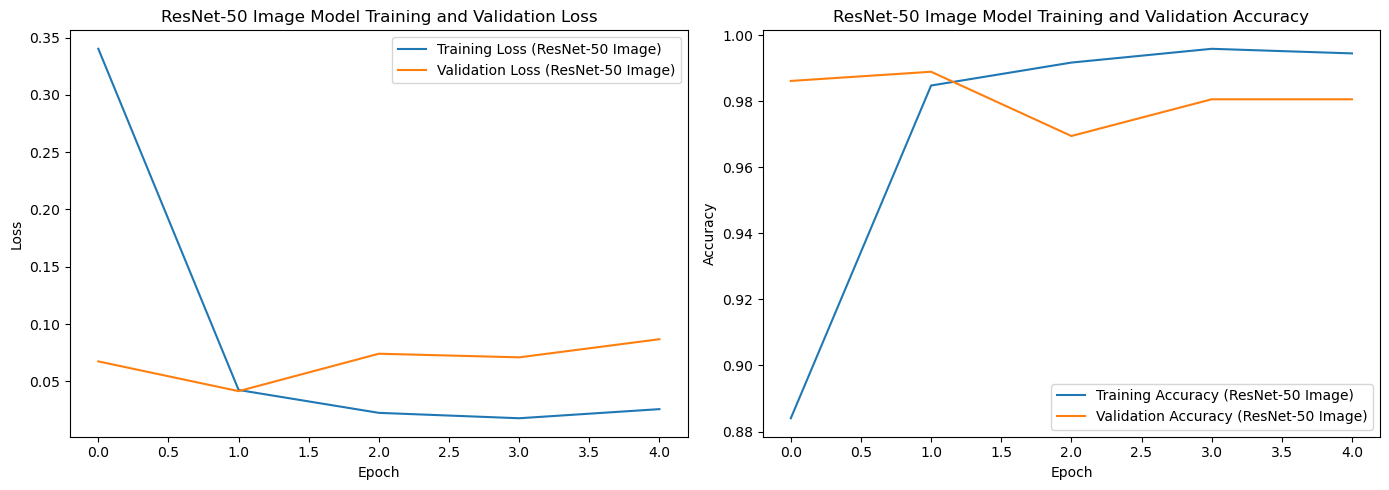

In [58]:
## Plot acc and loss

epochs_range = range(5)

train_loss_cnn_3_image = history.history['loss']
val_loss_cnn_3_image = history.history['val_loss']
train_accuracy_cnn_3_image = history.history['accuracy']
val_accuracy_cnn_3_image = history.history['val_accuracy']

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1) 
sns.lineplot(x=epochs_range, y=train_loss_cnn_3_image, label='Training Loss (ResNet-50 Image)')
sns.lineplot(x=epochs_range, y=val_loss_cnn_3_image, label='Validation Loss (ResNet-50 Image)')
plt.title('ResNet-50 Image Model Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
sns.lineplot(x=epochs_range, y=train_accuracy_cnn_3_image, label='Training Accuracy (ResNet-50 Image)')
sns.lineplot(x=epochs_range, y=val_accuracy_cnn_3_image, label='Validation Accuracy (ResNet-50 Image)')
plt.title('ResNet-50 Image Model Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout() 

In [ ]:
TEST_DIR = os.path.join(DATA_DIR, "validation", "images")

test_paths, test_labels, _ = load_images_from_directory(TEST_DIR)
test_images = preprocess_images(test_paths)

test_images = test_images[..., np.newaxis]
test_images_normalized = normalize_images(test_images)
test_images_rgb = np.repeat(test_images_normalized, 3, axis=-1)

test_labels = np.array(test_labels)
test_labels_cat = to_categorical(test_labels, num_classes=num_classes)



Loading test data...
Found classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Class 'crazing': 60 images
Class 'inclusion': 60 images
Class 'patches': 60 images
Class 'pitted_surface': 60 images
Class 'rolled-in_scale': 60 images
Class 'scratches': 60 images
Processing image 1/360
Processing image 101/360
Processing image 201/360
Processing image 301/360


In [ ]:
test_loss, test_accuracy = model.evaluate(test_images_rgb, test_labels_cat, verbose=0)

print(f"\nResNet50 Fine-Tuned Model Test Loss: {test_loss:.4f}")
print(f"ResNet50 Fine-Tuned Model Test Accuracy: {test_accuracy:.4f}")

y_pred_probs = model.predict(test_images_rgb, verbose=0)

y_pred = np.argmax(y_pred_probs, axis=1)


print(classification_report(test_labels, y_pred, target_names=class_names))

print(f"\nResNet50 Fine-Tuned Model Overall Test Accuracy (from sklearn): {accuracy_score(test_labels, y_pred):.4f}")
print(f"ResNet50 Fine-Tuned Model Weighted Precision: {precision_score(test_labels, y_pred, average='weighted'):.4f}")
print(f"ResNet50 Fine-Tuned Model Weighted Recall: {recall_score(test_labels, y_pred, average='weighted'):.4f}")
print(f"ResNet50 Fine-Tuned Model Weighted F1-Score: {f1_score(test_labels, y_pred, average='weighted'):.4f}")



ResNet50 Fine-Tuned Model Test Loss: 0.0868
ResNet50 Fine-Tuned Model Test Accuracy: 0.9806
                 precision    recall  f1-score   support

        crazing       1.00      1.00      1.00        60
      inclusion       1.00      0.88      0.94        60
        patches       1.00      1.00      1.00        60
 pitted_surface       0.97      1.00      0.98        60
rolled-in_scale       1.00      1.00      1.00        60
      scratches       0.92      1.00      0.96        60

       accuracy                           0.98       360
      macro avg       0.98      0.98      0.98       360
   weighted avg       0.98      0.98      0.98       360


ResNet50 Fine-Tuned Model Overall Test Accuracy (from sklearn): 0.9806
ResNet50 Fine-Tuned Model Weighted Precision: 0.9818
ResNet50 Fine-Tuned Model Weighted Recall: 0.9806
ResNet50 Fine-Tuned Model Weighted F1-Score: 0.9803



--- CNN Fine-Tuned Image Model Confusion Matrix (counts) ---
[[60  0  0  0  0  0]
 [ 0 53  0  2  0  5]
 [ 0  0 60  0  0  0]
 [ 0  0  0 60  0  0]
 [ 0  0  0  0 60  0]
 [ 0  0  0  0  0 60]]


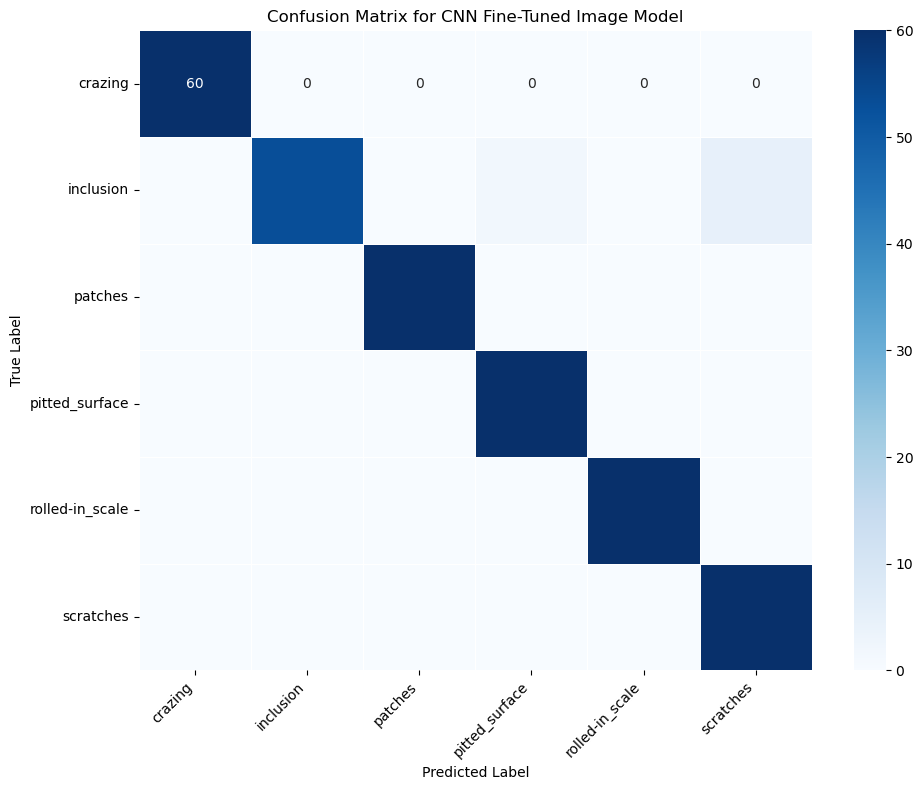

In [67]:
cm_cnn_image = confusion_matrix(test_labels, y_pred)

print("\n--- CNN Fine-Tuned Image Model Confusion Matrix (counts) ---")
print(cm_cnn_image)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_cnn_image,
            annot=True,           
            fmt='d',               
            cmap='Blues',         
            xticklabels=class_names,
            yticklabels=class_names,
            linewidths=0.5,
            cbar=True,
            annot_kws={"size": 10})

plt.title('Confusion Matrix for CNN Fine-Tuned Image Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

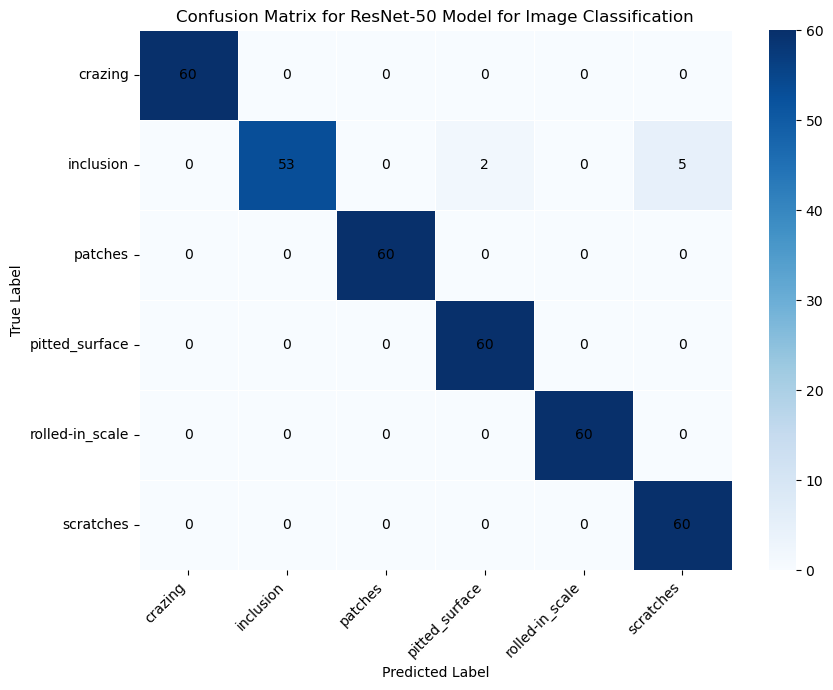

In [69]:
plt.figure(figsize=(9, 7))
ax = sns.heatmap(cm_cnn_image,
                 annot=False,
                 cmap='Blues',
                 xticklabels=class_names,
                 yticklabels=class_names,
                 linewidths=.5,
                 cbar=True)

# Manually annotate each cell
for i in range(cm_cnn_image.shape[0]):
    for j in range(cm_cnn_image.shape[1]):
        text = ax.text(j + 0.5, i + 0.5, str(cm_cnn_image[i, j]),
                       ha='center', va='center',
                       color='black', fontsize=10)

plt.title('Confusion Matrix for ResNet-50 Model for Image Classification')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### <a id='toc2_6_'></a>[Comparison](#toc0_)  